# EM2023 Mode Choice – Functional Data Dictionary

This notebook documents the analytical dataset, classifies its variables
by functional role, and establishes their preliminary use in the
exploratory data analysis (EDA) and subsequent modeling stages.

The original dataset will remain unchanged.

In [4]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns


In [5]:
data_path = Path(
    r"D:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\data\analytical\em2023_mode_choice_analytical_dataset.csv")

df = pd.read_csv(data_path, low_memory=False)

In [8]:
print(f"Records: {df.shape[0]:,}")
print(f"Variables: {df.shape[1]}")

display(pd.DataFrame({
    "variable": df.columns,
    "data_type": df.dtypes.astype(str).values
}))

Records: 100,174
Variables: 49


,variable,data_type
0,estra_hg,object
1,zat_ori,int64
2,localidad_ori,object
3,nom_mun_ori,object
4,zat_des,int64
5,localidad_des,object
6,nom_mun_des,object
7,hora_ini,float64
8,hora_fin,float64
9,duracion_min,float64


## 0 Dataframe Dictionary

In [9]:
dictionary_path = Path(
    r"D:\JAIME_ALEJANDRO_GARCIA\01_ACADEMIC\2026_fall\508_Transportation_planning\Transportatio_Planning\508_TP_Proyect\docs\EDA\01_EM2023_Functional_Data_Dictionary_v1.xlsx"
)

diccionario = pd.read_excel(dictionary_path,sheet_name="Functional Dictionary")

In [10]:
core_variables = [
    "key_viaje",
    "modo_principal_agrupado",
    "modo_principal_desagrupado",
    "territory_name_ori",
    "territory_name_des",
    "zat_centroid_distance_m",
    "hora_ini",
    "duracion_min",
    "edad",
    "sexo",
    "madre_cab_familia",
    "max_nivel_edu",
    "ocupacion_principal",
    "estra_hg",
    "hogar__ingre_mes_hg",
    "persona__licencia_cond_vigente",
    "hogar__tipo_viv",
    "hogar__perstotal_hg",
    "hogar__pers>5años_hg",
    "hogar__pers>18años_hg",
    "vehicle_records_in_household",
    "motivo_viaje",
    "frecuencia_viaje",
    "app_antes_vj",
    "t_acceso_min",
    "t_espera_min",
    "t_egreso_min"
]

In [11]:
assert len(core_variables) == 27
assert diccionario["variable"].is_unique

missing_variables = [var for var in core_variables
    if var not in diccionario["variable"].values]
assert len(missing_variables) == 0, missing_variables

diccionario["analysis_scope"] = diccionario["variable"].apply(
    lambda x: "core_27" if x in core_variables else "support_22"
)
diccionario.head(5)

,variable,functional_group,data_type,analytical_role,source_or_derived,eda_module,modeling_status,notes,analysis_scope
0,key_viaje,identifier,unique_identifier,trip_key,source,data_quality,exclude_from_predictors,Unique identifier for each trip.,core_27
1,key_pers,identifier,categorical_identifier,person_key,source,data_quality,auxiliary,Person identifier used to group trips.,support_22
2,key_pers_viaja,identifier,categorical_identifier,traveler_person_key,source,data_quality,auxiliary,Traveler identifier; provisionally retained al...,support_22
3,key_hg,identifier,categorical_identifier,household_key,source,data_quality,auxiliary,Household identifier used for grouped analysis.,support_22
4,modo_principal_agrupado,target,categorical_nominal,primary_target_candidate,source,travel_behavior,target_candidate,Aggregated main travel mode; candidate depende...,core_27


## Módulo 1. Dataset Overview and Quality

### 1. Dataset Overview and Quality

This section examines the structure, completeness, consistency, and
general quality of the EM2023 analytical dataset.

The purpose is to identify potential data quality issues before
conducting descriptive and exploratory analyses

#### 1.1. Dataset structure

In [12]:
print(f"Number of records: {df.shape[0]:,}")
print(f"Number of variables: {df.shape[1]}")

Number of records: 100,174
Number of variables: 49


In [13]:
display(df.head(10))

,estra_hg,zat_ori,localidad_ori,nom_mun_ori,zat_des,localidad_des,nom_mun_des,hora_ini,hora_fin,duracion_min,...,start_time_interpreted,end_time_interpreted,start_minutes_after_midnight,end_minutes_after_midnight,duration_calculated_min,crosses_midnight,territory_name_ori,territory_type_ori,territory_name_des,territory_type_des
0,3,374,Puente Aranda,Bogotá,745,Usme,Bogotá,7.00,8.00,60.0,...,07:00,08:00,420.0,480.0,60.0,False,Puente Aranda,Localidad,Usme,Localidad
1,3,745,Usme,Bogotá,374,Puente Aranda,Bogotá,17.00,18.58,95.0,...,17:00,18:35,1020.0,1115.0,95.0,False,Usme,Localidad,Puente Aranda,Localidad
2,3,374,Puente Aranda,Bogotá,384,Puente Aranda,Bogotá,8.00,8.50,30.0,...,08:00,08:30,480.0,510.0,30.0,False,Puente Aranda,Localidad,Puente Aranda,Localidad
3,3,384,Puente Aranda,Bogotá,374,Puente Aranda,Bogotá,13.50,13.55,3.0,...,13:30,13:33,810.0,813.0,3.0,False,Puente Aranda,Localidad,Puente Aranda,Localidad
4,3,374,Puente Aranda,Bogotá,379,Puente Aranda,Bogotá,14.00,14.25,15.0,...,14:00,14:15,840.0,855.0,15.0,False,Puente Aranda,Localidad,Puente Aranda,Localidad
5,3,379,Puente Aranda,Bogotá,374,Puente Aranda,Bogotá,15.58,16.00,25.0,...,15:35,16:00,935.0,960.0,25.0,False,Puente Aranda,Localidad,Puente Aranda,Localidad
6,3,374,Puente Aranda,Bogotá,703,Usme,Bogotá,11.83,11.95,7.0,...,11:50,11:57,710.0,717.0,7.0,False,Puente Aranda,Localidad,Usme,Localidad
7,3,703,Usme,Bogotá,374,Puente Aranda,Bogotá,13.00,13.25,15.0,...,13:00,13:15,780.0,795.0,15.0,False,Usme,Localidad,Puente Aranda,Localidad
8,3,374,Puente Aranda,Bogotá,663,Ciudad Bolivar,Bogotá,6.00,6.33,20.0,...,06:00,06:20,360.0,380.0,20.0,False,Puente Aranda,Localidad,Ciudad Bolivar,Localidad
9,3,663,Ciudad Bolivar,Bogotá,374,Puente Aranda,Bogotá,13.00,13.33,20.0,...,13:00,13:20,780.0,800.0,20.0,False,Ciudad Bolivar,Localidad,Puente Aranda,Localidad


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100174 entries, 0 to 100173
Data columns (total 49 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   estra_hg                        100174 non-null  object 
 1   zat_ori                         100174 non-null  int64  
 2   localidad_ori                   100174 non-null  object 
 3   nom_mun_ori                     100174 non-null  object 
 4   zat_des                         100174 non-null  int64  
 5   localidad_des                   100174 non-null  object 
 6   nom_mun_des                     100174 non-null  object 
 7   hora_ini                        100165 non-null  float64
 8   hora_fin                        100159 non-null  float64
 9   duracion_min                    100174 non-null  float64
 10  t_acceso_min                    57206 non-null   float64
 11  t_espera_min                    38381 non-null   float64
 12  t_egreso_min    

In [15]:
print("Dataset variables:", len(df.columns))
print("Dictionary variables:", len(diccionario))

missing_in_dictionary = set(df.columns) - set(diccionario["variable"])
missing_in_dataset = set(diccionario["variable"]) - set(df.columns)

print("Variables missing in dictionary:", missing_in_dictionary)
print("Variables missing in dataset:", missing_in_dataset)

Dataset variables: 49
Dictionary variables: 49
Variables missing in dictionary: set()
Variables missing in dataset: set()


#### 1.2. Data types

In [16]:
display(df.dtypes.value_counts().rename_axis("data_type").reset_index(name="count"))

,data_type,count
0,object,29
1,float64,12
2,int64,8


In [17]:
type_summary = diccionario[["variable", "functional_group", "data_type"]].copy()

type_summary["pandas_type"] = type_summary["variable"].map(df.dtypes.astype(str))

display(type_summary.sort_values( ["functional_group", "variable"]).reset_index(drop=True))

,variable,functional_group,data_type,pandas_type
0,zat_des,geographic,categorical_identifier,int64
1,zat_ori,geographic,categorical_identifier,int64
2,zat_centroid_distance_m,geographic_derived,numeric_continuous,float64
3,territory_name_des,geographic_harmonized,categorical_nominal,object
4,territory_name_ori,geographic_harmonized,categorical_nominal,object
5,territory_type_des,geographic_harmonized,categorical_nominal,object
6,territory_type_ori,geographic_harmonized,categorical_nominal,object
7,hogar__cod_upl_hg,geographic_household,categorical_identifier,int64
8,localidad_des,geographic_original,categorical_nominal,object
9,localidad_ori,geographic_original,categorical_nominal,object


#### 1.3. Missing values

In [18]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": df.isna().mean() * 100})

missing_summary = missing_summary.sort_values(
    "missing_percentage",
    ascending=False)

missing_data = missing_summary[missing_summary["missing_count"] > 0]

display(missing_data)

,missing_count,missing_percentage
t_espera_min,61793,61.685667
t_egreso_min,43018,42.943279
t_acceso_min,42968,42.893366
vehicle_type_values,39911,39.841675
crosses_midnight,24,0.023958
duration_calculated_min,24,0.023958
end_minutes_after_midnight,15,0.014974
end_time_interpreted,15,0.014974
hora_fin,15,0.014974
start_time_interpreted,9,0.008984


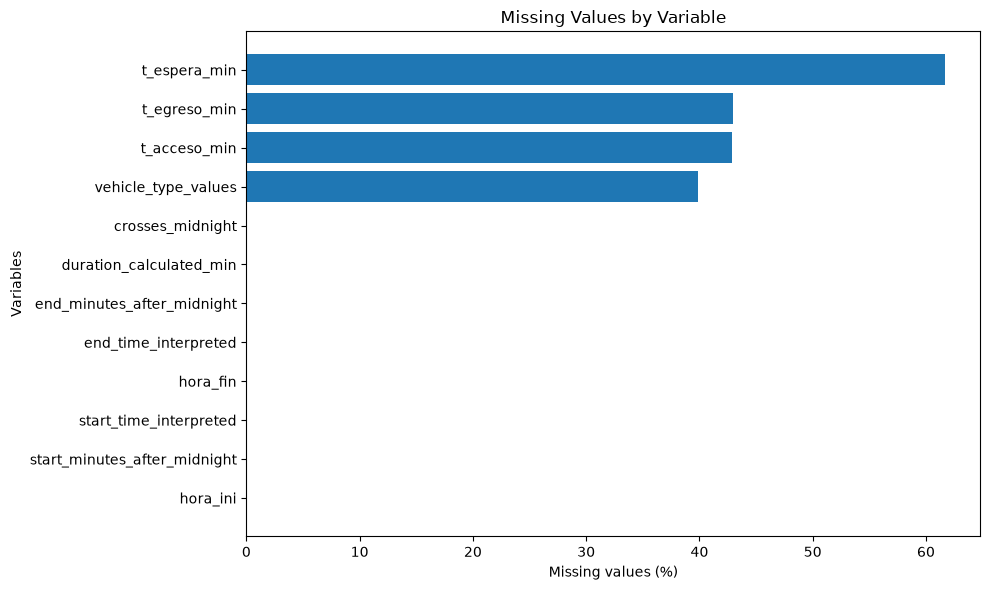

In [19]:
import matplotlib.pyplot as plt

missing_data = missing_summary[missing_summary["missing_count"] > 0]

plt.figure(figsize=(10, 6))
plt.barh(
    missing_data.index,
    missing_data["missing_percentage"]
)

plt.xlabel("Missing values (%)")
plt.ylabel("Variables")
plt.title("Missing Values by Variable")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

#### 1.4. Duplicate records and identifiers

In [26]:
print("Duplicated rows:", df.duplicated().sum())

Duplicated rows: 0


In [27]:
identifier_columns = [
    "key_viaje",
    "key_pers",
    "key_pers_viaja",
    "key_hg"
]

for col in identifier_columns:
    print(
        col,
        "| Unique:", df[col].nunique(),
        "| Missing:", df[col].isna().sum()
    )

key_viaje | Unique: 100174 | Missing: 0
key_pers | Unique: 48539 | Missing: 0
key_pers_viaja | Unique: 48539 | Missing: 0
key_hg | Unique: 21508 | Missing: 0


In [28]:
print("Unique trip IDs:", df["key_viaje"].nunique())
print("Total records:", len(df))
print("Unique trip IDs match records:",
      df["key_viaje"].is_unique)

Unique trip IDs: 100174
Total records: 100174
Unique trip IDs match records: True


#### 1.5. Categorical variables and special values

In [37]:
categorical_eda_variables = [
    "modo_principal_agrupado",
    "modo_principal_desagrupado",
    "territory_name_ori",
    "territory_name_des",
    "sexo",
    "madre_cab_familia",
    "max_nivel_edu",
    "ocupacion_principal",
    "estra_hg",
    "hogar__ingre_mes_hg",
    "persona__licencia_cond_vigente",
    "hogar__tipo_viv",
    "motivo_viaje",
    "frecuencia_viaje",
    "app_antes_vj"
]

category_summary = pd.DataFrame({
    "variable": categorical_eda_variables,
    "unique_categories": [
        df[col].nunique(dropna=True)
        for col in categorical_eda_variables
    ],
    "missing_values": [
        df[col].isna().sum()
        for col in categorical_eda_variables
    ]
})

display(category_summary)

,variable,unique_categories,missing_values
0,modo_principal_agrupado,11,0
1,modo_principal_desagrupado,33,0
2,territory_name_ori,55,0
3,territory_name_des,53,0
4,sexo,3,0
5,madre_cab_familia,3,0
6,max_nivel_edu,14,0
7,ocupacion_principal,24,0
8,estra_hg,7,0
9,hogar__ingre_mes_hg,12,0


In [38]:
for col in categorical_eda_variables:
    special_values = df[col].value_counts(dropna=False)

    if special_values.index.astype(str).isin(
        ["-", "No aplica", "No informa"]
    ).any():
        print(f"\n{col}")
        display(special_values.head(15))


madre_cab_familia


madre_cab_familia
No aplica    53756
No           33835
Sí           12583
Name: count, dtype: int64


estra_hg


estra_hg
2            25682
3            23373
No aplica    22511
1            13942
4             7390
5             4217
6             3059
Name: count, dtype: int64


persona__licencia_cond_vigente


persona__licencia_cond_vigente
No tiene                           57316
Vehículo particular                18272
No aplica                          12914
Moto                                5230
Vehículo particular/moto            4141
Vehículo parti./transp. público     1008
Transporte público                   639
Todas las anteriores                 608
Transporte público/moto               46
Name: count, dtype: int64

In [36]:
categorical_eda_variables = [
    "modo_principal_agrupado",
    "modo_principal_desagrupado",
    "territory_name_ori",
    "territory_name_des",
    "sexo",
    "madre_cab_familia",
    "max_nivel_edu",
    "ocupacion_principal",
    "estra_hg",
    "hogar__ingre_mes_hg",
    "persona__licencia_cond_vigente",
    "hogar__tipo_viv",
    "motivo_viaje",
    "frecuencia_viaje",
    "app_antes_vj"
]

category_summary = pd.DataFrame({
    "variable": categorical_eda_variables,
    "unique_categories": [
        df[col].nunique(dropna=True)
        for col in categorical_eda_variables
    ],
    "missing_values": [
        df[col].isna().sum()
        for col in categorical_eda_variables
    ]
})

display(category_summary)

,variable,unique_categories,missing_values
0,modo_principal_agrupado,11,0
1,modo_principal_desagrupado,33,0
2,territory_name_ori,55,0
3,territory_name_des,53,0
4,sexo,3,0
5,madre_cab_familia,3,0
6,max_nivel_edu,14,0
7,ocupacion_principal,24,0
8,estra_hg,7,0
9,hogar__ingre_mes_hg,12,0


#### 1.6. Numerical ranges and consistency

In [39]:
numerical_eda_variables = [
    "hora_ini",
    "hora_fin",
    "duracion_min",
    "duration_calculated_min",
    "start_minutes_after_midnight",
    "end_minutes_after_midnight",
    "edad",
    "hogar__perstotal_hg",
    "hogar__pers>5años_hg",
    "hogar__pers>18años_hg",
    "vehicle_records_in_household",
    "t_acceso_min",
    "t_espera_min",
    "t_egreso_min",
    "zat_centroid_distance_m"
]

display(df[numerical_eda_variables].describe().T)

,count,mean,std,min,25%,50%,75%,max
hora_ini,100165.0,11.691803,4.655407,0.02,7.050000,11.500000,15.500000,23.980000
hora_fin,100159.0,12.478786,4.699880,0.03,8.020000,12.200000,16.480000,23.980000
duracion_min,100174.0,48.104095,40.973956,3.00,16.000000,33.000000,65.000000,485.000000
duration_calculated_min,100150.0,48.113909,41.223589,3.00,16.000000,33.000000,65.000000,1439.000000
start_minutes_after_midnight,100165.0,701.509360,279.324282,1.00,423.000000,690.000000,930.000000,1439.000000
end_minutes_after_midnight,100159.0,748.726764,281.992439,2.00,481.000000,732.000000,989.000000,1439.000000
edad,100174.0,38.690339,19.668571,5.00,23.000000,37.000000,54.000000,99.000000
hogar__perstotal_hg,100174.0,3.588596,1.545400,1.00,3.000000,3.000000,4.000000,11.000000
hogar__pers>5años_hg,100174.0,3.461257,1.477543,1.00,2.000000,3.000000,4.000000,11.000000
hogar__pers>18años_hg,100174.0,2.795516,1.209406,1.00,2.000000,3.000000,4.000000,10.000000


### 2. analisis por tipo de modo -->

#### 2.1. Aggregated travel mode distribution

In [40]:
mode_counts = (
    df["modo_principal_agrupado"]
    .value_counts(dropna=False)
    .rename_axis("travel_mode")
    .reset_index(name="trips")
)

mode_counts["percentage"] = (
    mode_counts["trips"] / len(df) * 100
)

mode_counts["cumulative_percentage"] = (
    mode_counts["percentage"].cumsum()
)

display(mode_counts.round(2))

,travel_mode,trips,percentage,cumulative_percentage
0,TRANSPORTE PÚBLICO,29407,29.36,29.36
1,A PIE > 15 MIN,24932,24.89,54.24
2,AUTO,12586,12.56,66.81
3,A PIE <15 MIN,12392,12.37,79.18
4,MOTO,6247,6.24,85.42
5,BICICLETA,6104,6.09,91.51
6,TAXI OCUPADO,3267,3.26,94.77
7,TRANSPORTE ESCOLAR,2058,2.05,96.82
8,ESPECIAL OCUPADO,1982,1.98,98.80
9,INFORMAL,867,0.87,99.67


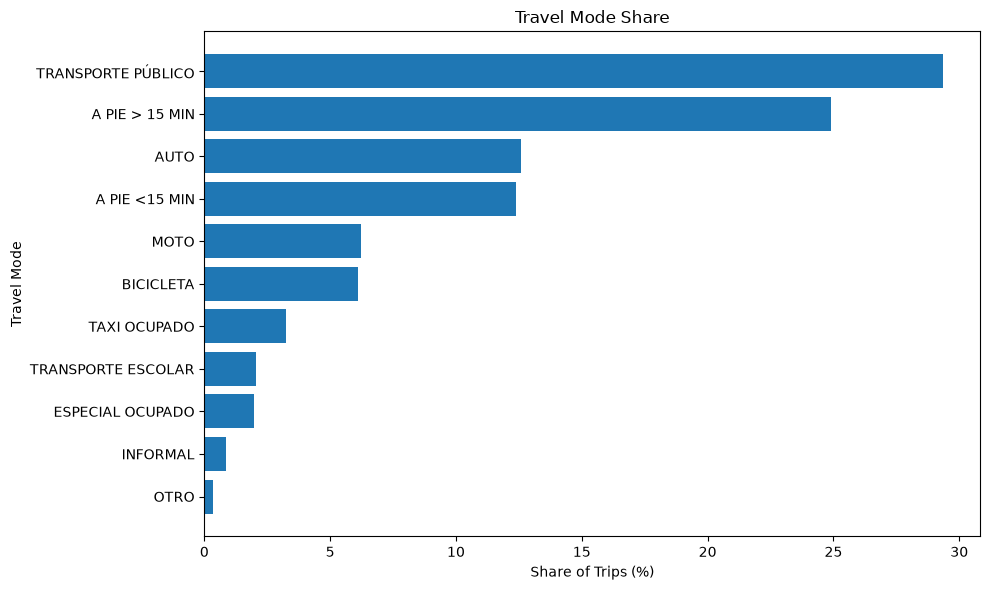

In [43]:
plt.figure(figsize=(10, 6))

plt.barh(
    mode_counts["travel_mode"][::-1],
    mode_counts["percentage"][::-1]
)

plt.title("Travel Mode Share")
plt.xlabel("Share of Trips (%)")
plt.ylabel("Travel Mode")

plt.tight_layout()
plt.show()

#### 2.2. Disaggregated travel mode distribution

In [44]:
mode_detail_counts = (
    df["modo_principal_desagrupado"]
    .value_counts(dropna=False)
    .rename_axis("travel_mode")
    .reset_index(name="trips")
)

mode_detail_counts["percentage"] = (
    mode_detail_counts["trips"] / len(df) * 100
)

mode_detail_counts["cumulative_percentage"] = (
    mode_detail_counts["percentage"].cumsum()
)

display(mode_detail_counts.round(2))

,travel_mode,trips,percentage,cumulative_percentage
0,A pie (Mayores de 15 min),24932,24.89,24.89
1,A pie (Menores de 15 min),12392,12.37,37.26
2,TransMilenio,12296,12.27,49.53
3,SITP – Urbano/ Complementario/Especial /Provi...,12160,12.14,61.67
4,Vehículo privado como conductor,8110,8.10,69.77
5,Bicicleta convencional como conductor,5626,5.62,75.38
6,Motocicleta como conductor,5547,5.54,80.92
7,Vehículo privado como pasajero,3758,3.75,84.67
8,Bus/Buseta/Microbús intermunicipal,3463,3.46,88.13
9,Taxi convencional,2217,2.21,90.34


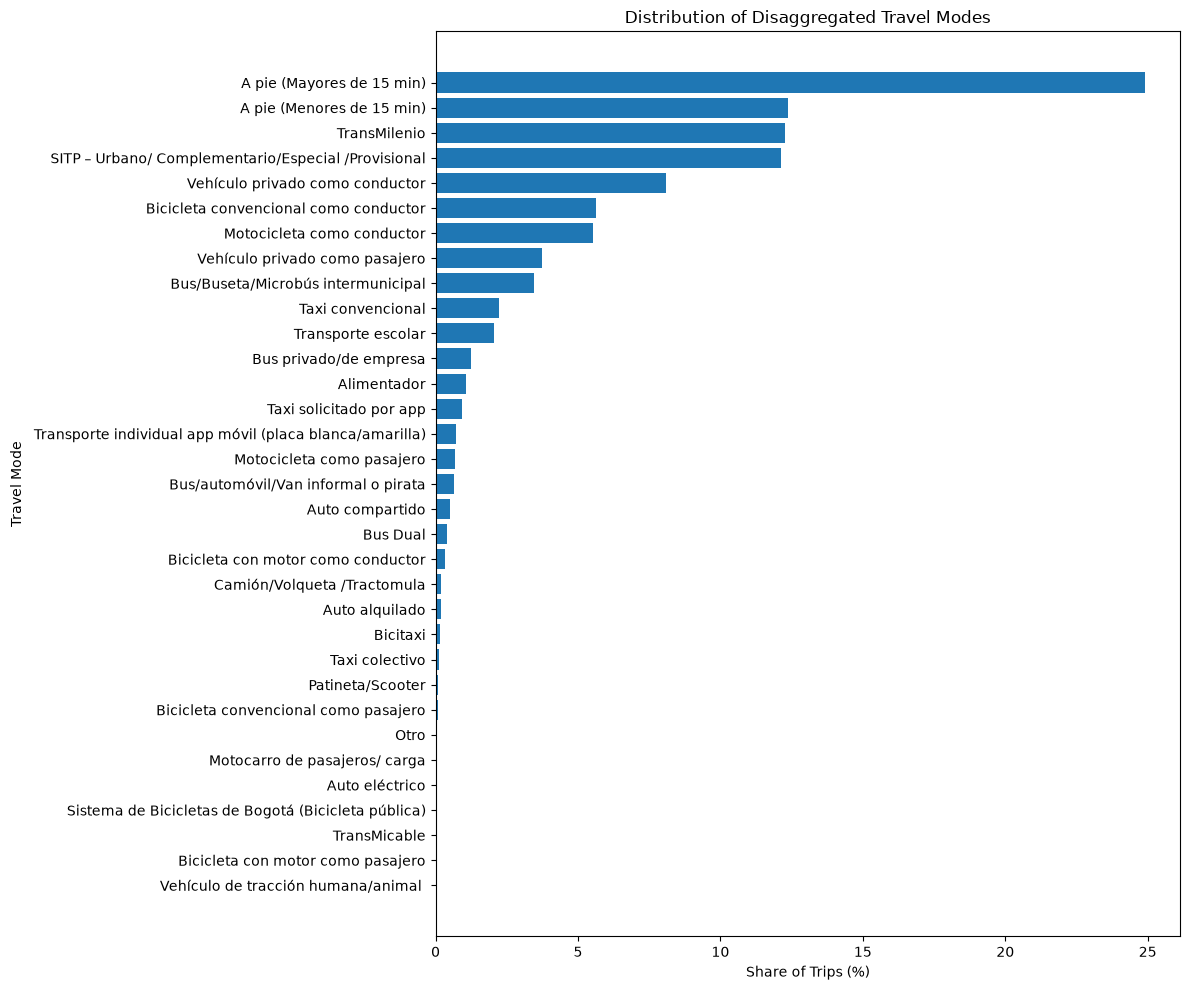

In [45]:
plt.figure(figsize=(12, 10))

plt.barh(
    mode_detail_counts["travel_mode"][::-1],
    mode_detail_counts["percentage"][::-1]
)

plt.title("Distribution of Disaggregated Travel Modes")
plt.xlabel("Share of Trips (%)")
plt.ylabel("Travel Mode")

plt.tight_layout()
plt.show()

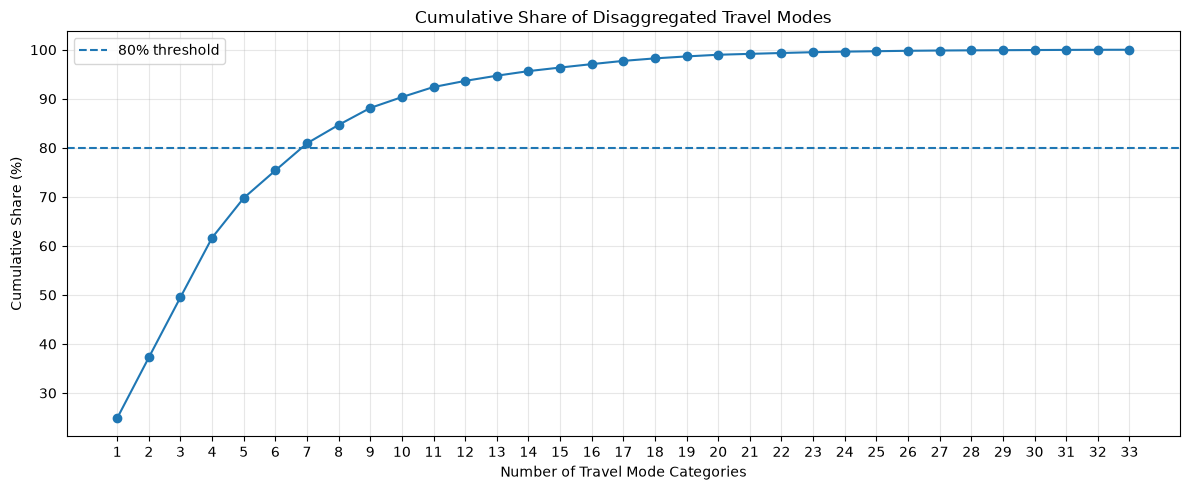

In [46]:
plt.figure(figsize=(12, 5))

plt.plot(
    range(1, len(mode_detail_counts) + 1),
    mode_detail_counts["cumulative_percentage"],
    marker="o"
)

plt.axhline(80, linestyle="--", label="80% threshold")

plt.title("Cumulative Share of Disaggregated Travel Modes")
plt.xlabel("Number of Travel Mode Categories")
plt.ylabel("Cumulative Share (%)")
plt.xticks(range(1, len(mode_detail_counts) + 1))
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### 2.3. Cross-tabulation of aggregated and disaggregated travel modes

In [47]:
mode_cross_tab = pd.crosstab(
    df["modo_principal_desagrupado"],
    df["modo_principal_agrupado"],
    margins=True
)

display(mode_cross_tab)

modo_principal_agrupado,A PIE <15 MIN,A PIE > 15 MIN,AUTO,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO,All
modo_principal_desagrupado,,,,,,,,,,,,
Bus Dual,0,0,0,0,0,0,0,0,0,0,401,401
A pie (Mayores de 15 min),0,24932,0,0,0,0,0,0,0,0,0,24932
A pie (Menores de 15 min),12392,0,0,0,0,0,0,0,0,0,0,12392
Alimentador,0,0,0,0,0,0,0,0,0,0,1059,1059
Auto alquilado,0,0,177,0,0,0,0,0,0,0,0,177
Auto compartido,0,0,511,0,0,0,0,0,0,0,0,511
Auto eléctrico,0,0,30,0,0,0,0,0,0,0,0,30
Bicicleta con motor como conductor,0,0,0,341,0,0,0,0,0,0,0,341
Bicicleta con motor como pasajero,0,0,0,23,0,0,0,0,0,0,0,23


In [48]:
mode_cross_tab_pct = pd.crosstab(
    df["modo_principal_desagrupado"],
    df["modo_principal_agrupado"],
    normalize="index"
) * 100

display(mode_cross_tab_pct.round(2))

modo_principal_agrupado,A PIE <15 MIN,A PIE > 15 MIN,AUTO,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
modo_principal_desagrupado,,,,,,,,,,,
Bus Dual,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0
A pie (Mayores de 15 min),0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A pie (Menores de 15 min),100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Alimentador,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0
Auto alquilado,0.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Auto compartido,0.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Auto eléctrico,0.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Bicicleta con motor como conductor,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Bicicleta con motor como pasajero,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [49]:
mode_mapping_check = pd.crosstab(
    df["modo_principal_desagrupado"],
    df["modo_principal_agrupado"]
)

mapping_summary = pd.DataFrame({
    "aggregated_categories_per_mode": (mode_mapping_check > 0).sum(axis=1),
    "number_of_trips": mode_mapping_check.sum(axis=1)
})

display(mapping_summary)

print(
    "Disaggregated categories mapped to exactly one group:",
    (mapping_summary["aggregated_categories_per_mode"] == 1).all()
)

,aggregated_categories_per_mode,number_of_trips
modo_principal_desagrupado,,
Bus Dual,1,401
A pie (Mayores de 15 min),1,24932
A pie (Menores de 15 min),1,12392
Alimentador,1,1059
Auto alquilado,1,177
Auto compartido,1,511
Auto eléctrico,1,30
Bicicleta con motor como conductor,1,341
Bicicleta con motor como pasajero,1,23


Disaggregated categories mapped to exactly one group: True


#### 2.4. Distribution of Trip Purposes

In [50]:
purpose_counts = (
    df["motivo_viaje"]
    .value_counts(dropna=False)
    .rename_axis("trip_purpose")
    .reset_index(name="trips")
)

purpose_counts["percentage"] = (
    purpose_counts["trips"] / len(df) * 100
)

purpose_counts["cumulative_percentage"] = (
    purpose_counts["percentage"].cumsum()
)

display(purpose_counts.round(2))

,trip_purpose,trips,percentage,cumulative_percentage
0,A regresar al hogar,47672,47.59,47.59
1,A trabajar,20821,20.78,68.37
2,A Estudiar,9417,9.40,77.77
3,A realizar algún trámite personal,4904,4.90,82.67
4,A realizar compras,4662,4.65,87.32
5,A acompañar a alguien sin remuneración,3899,3.89,91.22
6,A asuntos médicos personales,3669,3.66,94.88
7,A visitar a alguien,1450,1.45,96.33
8,A realizar actividades recreativas y culturales,1235,1.23,97.56
9,A realizar actividades físicas y/o deportivas,997,1.00,98.55


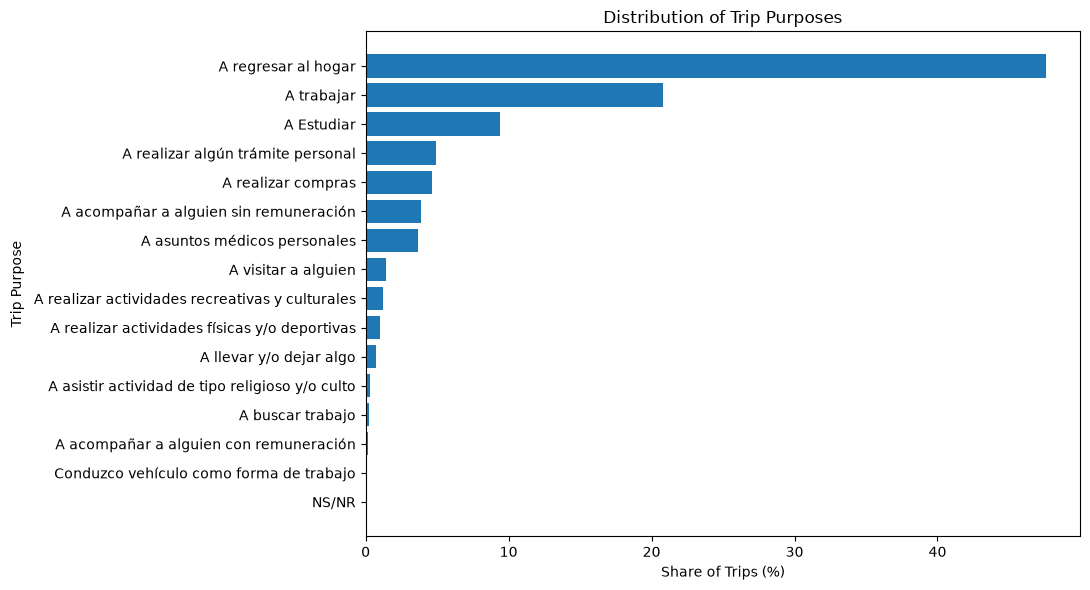

In [51]:
plt.figure(figsize=(11, 6))

plt.barh(
    purpose_counts["trip_purpose"][::-1],
    purpose_counts["percentage"][::-1]
)

plt.title("Distribution of Trip Purposes")
plt.xlabel("Share of Trips (%)")
plt.ylabel("Trip Purpose")

plt.tight_layout()
plt.show()

#### 2.5. Trip Purpose by Aggregated Travel Mode

In [52]:
purpose_mode_counts = pd.crosstab(
    df["motivo_viaje"],
    df["modo_principal_agrupado"]
)

display(purpose_mode_counts)

modo_principal_agrupado,A PIE <15 MIN,A PIE > 15 MIN,AUTO,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
motivo_viaje,,,,,,,,,,,
A Estudiar,1776,3369,374,364,138,82,272,5,82,983,1972
A acompañar a alguien con remuneración,34,55,22,6,0,4,3,0,5,0,17
A acompañar a alguien sin remuneración,926,1365,599,156,44,39,162,4,150,2,452
A asistir actividad de tipo religioso y/o culto,62,98,44,5,2,4,3,3,29,0,44
A asuntos médicos personales,89,460,543,62,103,53,55,7,507,0,1790
A buscar trabajo,8,49,4,24,1,1,5,0,2,0,143
A llevar y/o dejar algo,144,219,100,56,4,8,49,4,6,0,102
A realizar actividades físicas y/o deportivas,278,482,71,92,3,2,16,5,10,2,36
A realizar actividades recreativas y culturales,220,381,322,49,37,10,25,3,60,4,124


In [53]:
purpose_mode_share = pd.crosstab(
    df["motivo_viaje"],
    df["modo_principal_agrupado"],
    normalize="index"
) * 100

display(purpose_mode_share.round(2))

modo_principal_agrupado,A PIE <15 MIN,A PIE > 15 MIN,AUTO,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
motivo_viaje,,,,,,,,,,,
A Estudiar,18.86,35.78,3.97,3.87,1.47,0.87,2.89,0.05,0.87,10.44,20.94
A acompañar a alguien con remuneración,23.29,37.67,15.07,4.11,0.00,2.74,2.05,0.00,3.42,0.00,11.64
A acompañar a alguien sin remuneración,23.75,35.01,15.36,4.00,1.13,1.00,4.15,0.10,3.85,0.05,11.59
A asistir actividad de tipo religioso y/o culto,21.09,33.33,14.97,1.70,0.68,1.36,1.02,1.02,9.86,0.00,14.97
A asuntos médicos personales,2.43,12.54,14.80,1.69,2.81,1.44,1.50,0.19,13.82,0.00,48.79
A buscar trabajo,3.38,20.68,1.69,10.13,0.42,0.42,2.11,0.00,0.84,0.00,60.34
A llevar y/o dejar algo,20.81,31.65,14.45,8.09,0.58,1.16,7.08,0.58,0.87,0.00,14.74
A realizar actividades físicas y/o deportivas,27.88,48.35,7.12,9.23,0.30,0.20,1.60,0.50,1.00,0.20,3.61
A realizar actividades recreativas y culturales,17.81,30.85,26.07,3.97,3.00,0.81,2.02,0.24,4.86,0.32,10.04


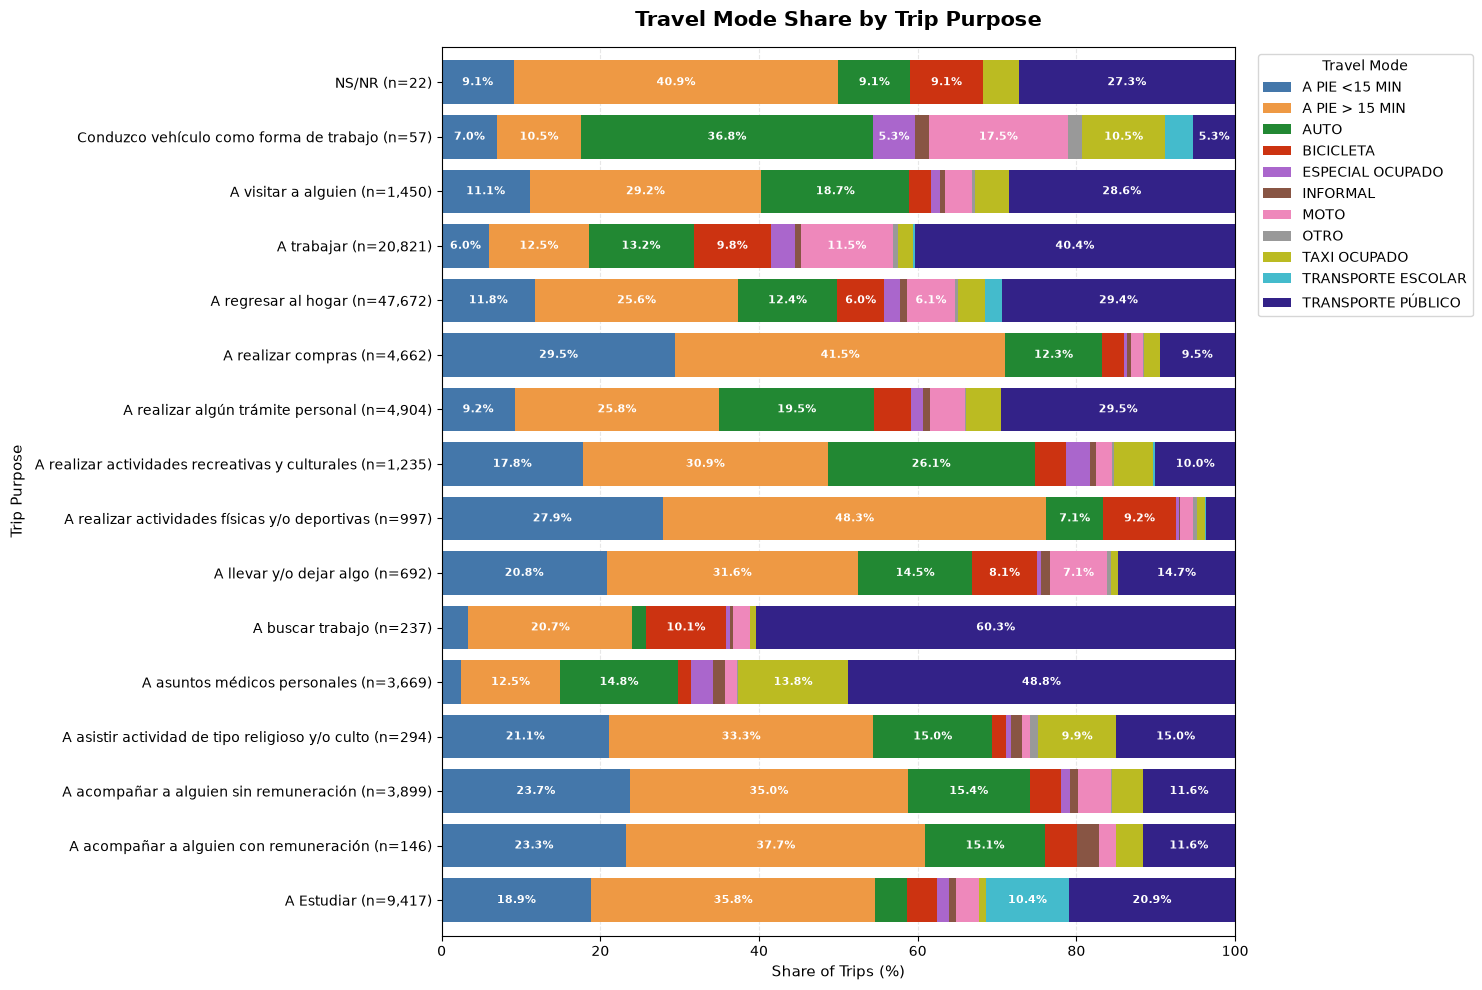

In [62]:

import matplotlib.pyplot as plt

# Define a unique color for each travel mode
mode_colors = {
    "A PIE <15 MIN": "#4477AA",
    "A PIE > 15 MIN": "#EE9944",
    "AUTO": "#228833",
    "BICICLETA": "#CC3311",
    "ESPECIAL OCUPADO": "#AA66CC",
    "INFORMAL": "#885544",
    "MOTO": "#EE88BB",
    "OTRO": "#999999",
    "TAXI OCUPADO": "#BBBB22",
    "TRANSPORTE ESCOLAR": "#44BBCC",
    "TRANSPORTE PÚBLICO": "#332288"
}

# Assign colors following the column order
colors = [mode_colors[col] for col in purpose_mode_share.columns]

# Create the figure
fig, ax = plt.subplots(figsize=(15, 10))

purpose_mode_share.plot(
    kind="barh",
    stacked=True,
    color=colors,
    width=0.8,
    ax=ax
)

# Add percentage labels to sufficiently large segments
for container in ax.containers:
    labels = [
        f"{value:.1f}%" if value >= 5 else ""
        for value in container.datavalues
    ]

    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=8,
        color="white",
        fontweight="bold"
    )

# Formatting
ax.set_title(
    "Travel Mode Share by Trip Purpose",
    fontsize=15,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Share of Trips (%)", fontsize=11)
ax.set_ylabel("Trip Purpose", fontsize=11)
ax.set_xlim(0, 100)

ax.legend(
    title="Travel Mode",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=True
)

purpose_counts = df["motivo_viaje"].value_counts()

purpose_labels = [
    f"{purpose} (n={purpose_counts.get(purpose, 0):,})"
    for purpose in purpose_mode_share.index
]

ax.set_yticklabels(purpose_labels)

ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


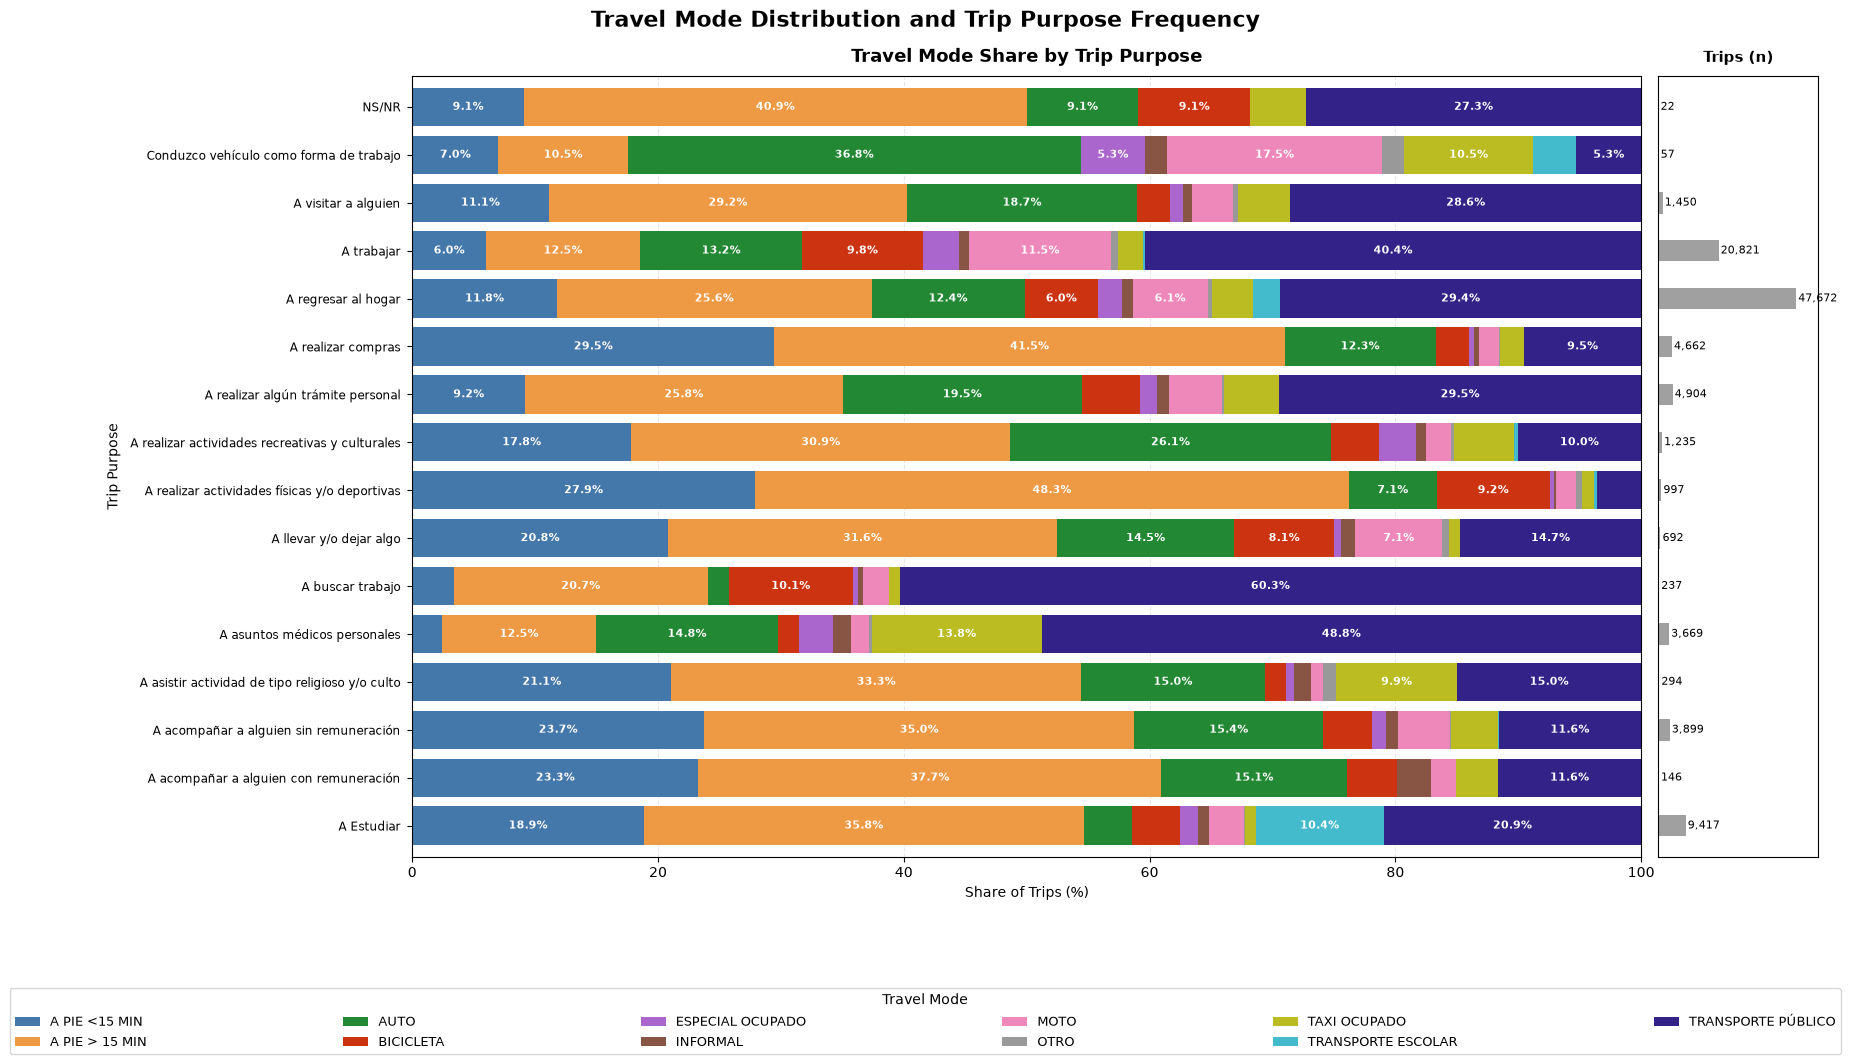

In [71]:

import matplotlib.pyplot as plt
import numpy as np

# ==================================================
# 1. PREPARE DATA
# ==================================================

purpose_counts = df["motivo_viaje"].value_counts()
purpose_counts = purpose_counts.reindex(purpose_mode_share.index)

colors = [mode_colors[col] for col in purpose_mode_share.columns]

# ==================================================
# 2. CREATE FIGURE
# ==================================================

fig, (ax_share, ax_count) = plt.subplots(
    ncols=2,
    figsize=(19, 11),
    sharey=True,
    gridspec_kw={
        "width_ratios": [5, 0.65],
        "wspace": 0.025
    }
)

# ==================================================
# 3. MAIN CHART: TRAVEL MODE SHARE
# ==================================================

purpose_mode_share.plot(
    kind="barh",
    stacked=True,
    color=colors,
    width=0.8,
    ax=ax_share,
    legend=False
)

# Set trip purpose labels and order
ax_share.set_yticks(np.arange(len(purpose_mode_share.index)))
ax_share.set_yticklabels(purpose_mode_share.index)
ax_share.invert_yaxis()

# Add percentage labels to segments >= 5%
for container in ax_share.containers:

    labels = [
        f"{value:.1f}%" if value >= 5 else ""
        for value in container.datavalues
    ]

    ax_share.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=8,
        color="white",
        fontweight="bold"
    )

# Main chart formatting
ax_share.set_title(
    "Travel Mode Share by Trip Purpose",
    fontsize=13,
    fontweight="bold",
    pad=10
)

ax_share.set_xlabel("Share of Trips (%)", fontsize=10)
ax_share.set_ylabel("Trip Purpose", fontsize=10)
ax_share.set_xlim(0, 100)

ax_share.tick_params(
    axis="y",
    labelsize=8.5,
    pad=5
)

ax_share.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax_share.set_axisbelow(True)

# ==================================================
# 4. SECONDARY CHART: TRIP FREQUENCY
# ==================================================

y_positions = np.arange(len(purpose_counts))

ax_count.barh(
    y_positions,
    purpose_counts.values,
    color="#A0A0A0",
    height=0.45
)

# Align frequency bars with main chart
ax_count.set_yticks(y_positions)
ax_count.tick_params(
    axis="y",
    left=False,
    labelleft=False
)

ax_count.invert_yaxis()

# Add trip count labels
for i, value in enumerate(purpose_counts):

    ax_count.text(
        value + purpose_counts.max() * 0.015,
        i,
        f"{value:,.0f}",
        va="center",
        fontsize=8
    )

# Frequency chart formatting
ax_count.set_xlim(
    0,
    purpose_counts.max() * 1.16
)

ax_count.set_xticks([])
ax_count.set_xlabel("")

ax_count.set_title(
    "Trips (n)",
    fontsize=11,
    fontweight="bold",
    pad=10
)

ax_count.grid(
    axis="x",
    linestyle="--",
    alpha=0.2
)

ax_count.set_axisbelow(True)

# ==================================================
# 5. FULL-WIDTH HORIZONTAL LEGEND
# ==================================================

handles, labels = ax_share.get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Travel Mode",
    loc="lower left",
    bbox_to_anchor=(0.015, 0.015, 0.97, 0.10),
    bbox_transform=fig.transFigure,
    mode="expand",
    ncol=6,
    fontsize=9,
    title_fontsize=10,
    frameon=True
)

# ==================================================
# 6. OVERALL TITLE
# ==================================================

fig.suptitle(
    "Travel Mode Distribution and Trip Purpose Frequency",
    fontsize=16,
    fontweight="bold",
    x=0.50,
    y=0.97
)

# ==================================================
# 7. FINAL LAYOUT
# ==================================================

fig.subplots_adjust(
    left=0.23,
    right=0.97,
    top=0.91,
    bottom=0.20
)

plt.show()


#### 2.6: Socioeconomic Variables Distribution

##### 2.6.1	edad

In [72]:
# Age distribution: descriptive statistics

age_summary = df["edad"].describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
)

display(age_summary)

count    100174.000000
mean         38.690339
std          19.668571
min           5.000000
10%          13.000000
25%          23.000000
50%          37.000000
75%          54.000000
90%          66.000000
max          99.000000
Name: edad, dtype: float64

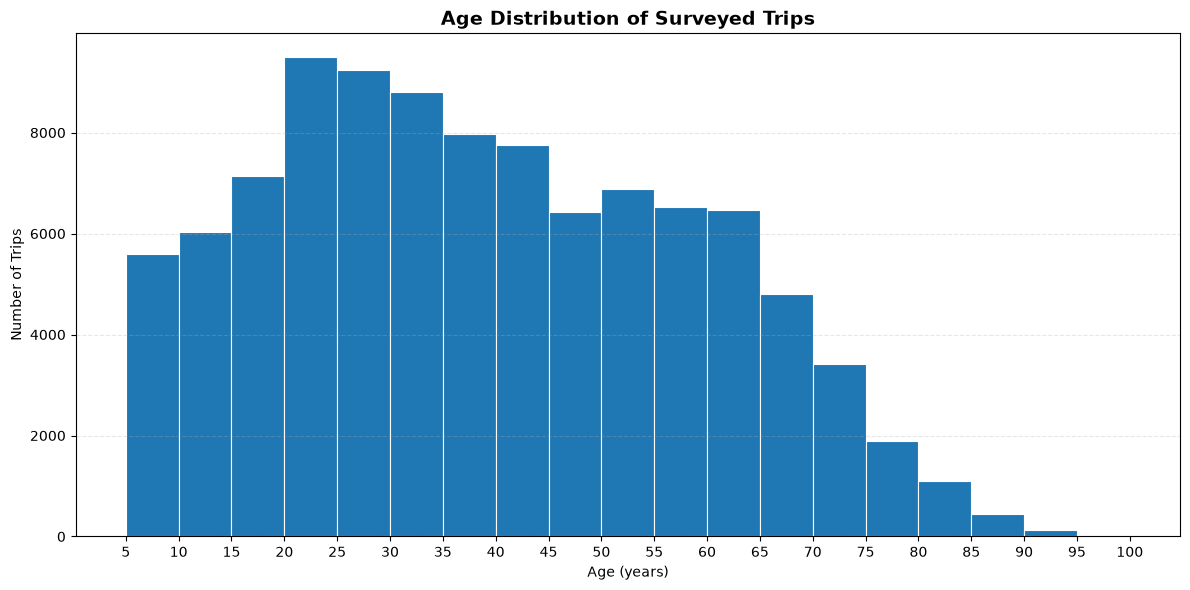

In [73]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.hist(
    df["edad"].dropna(),
    bins=range(5, 101, 5),
    edgecolor="white",
    linewidth=0.8
)

plt.title("Age Distribution of Surveyed Trips", fontsize=14, fontweight="bold")
plt.xlabel("Age (years)")
plt.ylabel("Number of Trips")
plt.xticks(range(5, 101, 5))
plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


In [74]:

# Define age groups for descriptive analysis

age_bins = [5, 12, 18, 25, 35, 45, 55, 65, 75, 100]

age_labels = [
    "5-11",
    "12-17",
    "18-24",
    "25-34",
    "35-44",
    "45-54",
    "55-64",
    "65-74",
    "75+"
]

age_groups = pd.cut(
    df["edad"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

# Calculate frequencies and percentages
age_group_summary = (
    age_groups.value_counts(sort=False)
    .rename("trip_count")
    .to_frame()
)

age_group_summary["percentage"] = (
    age_group_summary["trip_count"] / len(df) * 100
)

display(age_group_summary.round(2))


,trip_count,percentage
edad,,
5-11,7870,7.86
12-17,7364,7.35
18-24,13035,13.01
25-34,18050,18.02
35-44,15725,15.70
45-54,13311,13.29
55-64,12994,12.97
65-74,8228,8.21
75+,3597,3.59


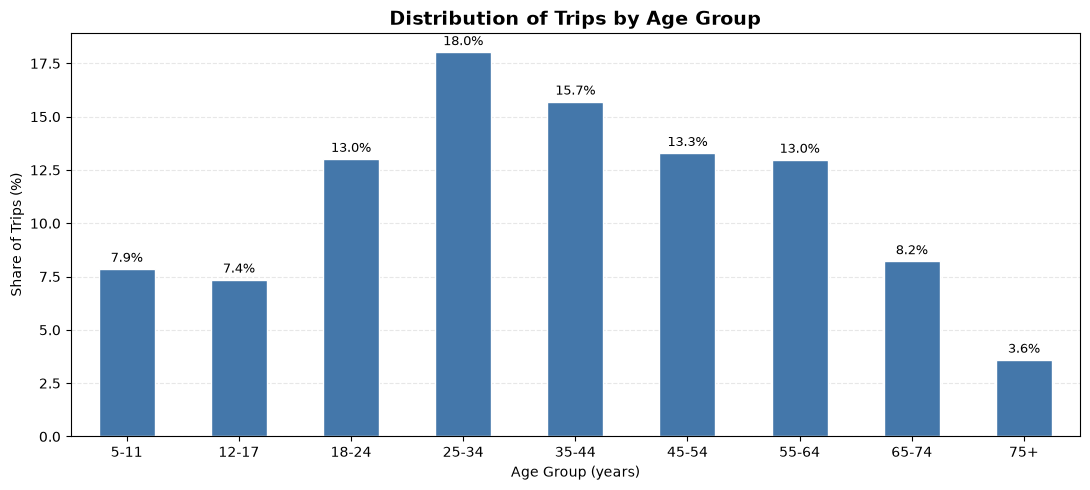

In [75]:

fig, ax = plt.subplots(figsize=(11, 5))

age_group_summary["percentage"].plot(
    kind="bar",
    color="#4477AA",
    edgecolor="white",
    ax=ax
)

ax.set_title(
    "Distribution of Trips by Age Group",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Age Group (years)")
ax.set_ylabel("Share of Trips (%)")

ax.bar_label(
    ax.containers[0],
    fmt="%.1f%%",
    padding=3,
    fontsize=9
)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [76]:
print("Total observations:", len(df))
print("Assigned to age groups:", age_groups.notna().sum())
print("Unassigned observations:", age_groups.isna().sum())

Total observations: 100174
Assigned to age groups: 100174
Unassigned observations: 0


##### 2.6.2	sexo

In [77]:
# Sex distribution

sex_summary = (
    df["sexo"]
    .value_counts(dropna=False)
    .rename("trip_count")
    .to_frame()
)

sex_summary["percentage"] = (
    sex_summary["trip_count"] / len(df) * 100
)

display(sex_summary.round(2))

,trip_count,percentage
sexo,,
Mujer,52080,51.99
Hombre,48077,47.99
Intersexual,17,0.02


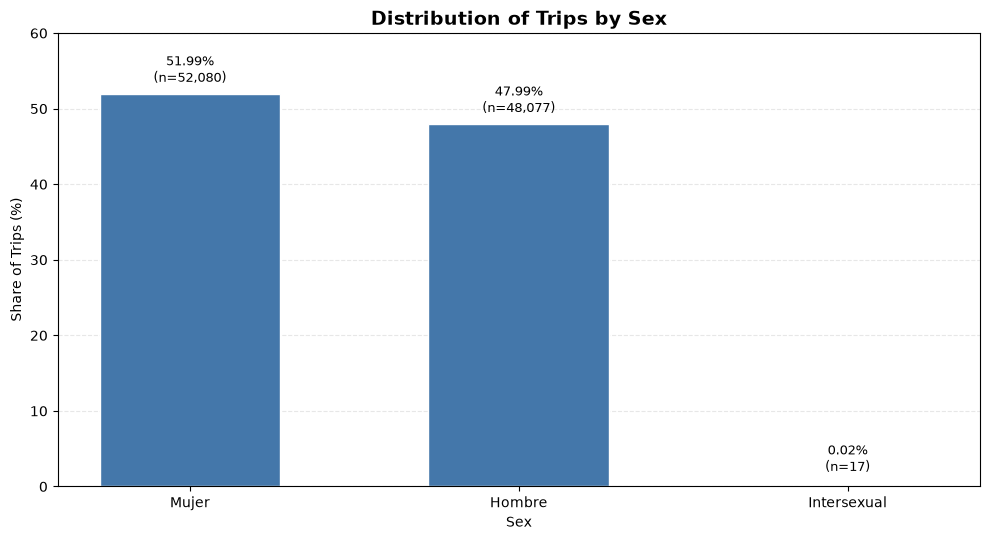

In [80]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5.5))

# Create bars
bars = ax.bar(
    sex_summary.index.astype(str),
    sex_summary["percentage"],
    color="#4477AA",
    edgecolor="white",
    width=0.55
)

# Add one label per category
for i, (bar, row) in enumerate(
    zip(bars, sex_summary.itertuples())
):
    value = row.percentage
    count = row.trip_count

    # Place labels above each bar
    label_y = max(value + 1.0, 1.5)

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        label_y,
        f"{value:.2f}%\n(n={count:,})",
        ha="center",
        va="bottom",
        fontsize=9
    )

# Formatting
ax.set_title(
    "Distribution of Trips by Sex",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Sex")
ax.set_ylabel("Share of Trips (%)")
ax.set_ylim(0, 60)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


##### 2.6.3	madre_cab_familia

In [81]:

# Mother as household head: frequency distribution

mother_head_summary = (
    df["madre_cab_familia"]
    .value_counts(dropna=False)
    .rename("trip_count")
    .to_frame()
)

mother_head_summary["percentage"] = (
    mother_head_summary["trip_count"] / len(df) * 100
)

display(mother_head_summary.round(2))


,trip_count,percentage
madre_cab_familia,,
No aplica,53756,53.66
No,33835,33.78
Sí,12583,12.56


In [82]:
print(df["madre_cab_familia"].unique())
print("\nData type:", df["madre_cab_familia"].dtype)

['No aplica' 'Sí' 'No']

Data type: object


In [83]:
display(
    diccionario.loc[
        diccionario["variable"] == "madre_cab_familia"
    ]
)

,variable,functional_group,data_type,analytical_role,source_or_derived,eda_module,modeling_status,notes,analysis_scope
29,madre_cab_familia,personal_family,categorical_binary_or_nominal,mother_head_of_household,source,socioeconomic,pending_validation,Family-status indicator; confirm official defi...,core_27


In [84]:
# Mother as household head by sex

mother_head_by_sex = pd.crosstab(
    df["sexo"],
    df["madre_cab_familia"],
    margins=True
)

display(mother_head_by_sex)

madre_cab_familia,No,No aplica,Sí,All
sexo,,,,
Hombre,0,48077,0,48077
Intersexual,0,17,0,17
Mujer,33835,5662,12583,52080
All,33835,53756,12583,100174


In [85]:
# Row percentages by sex

mother_head_by_sex_pct = pd.crosstab(
    df["sexo"],
    df["madre_cab_familia"],
    normalize="index"
) * 100

display(mother_head_by_sex_pct.round(2))

madre_cab_familia,No,No aplica,Sí
sexo,,,
Hombre,0.00,100.00,0.00
Intersexual,0.00,100.00,0.00
Mujer,64.97,10.87,24.16


In [86]:
# Mother as household head by age group
# Restrict analysis to women

women_df = df[df["sexo"] == "Mujer"].copy()

mother_head_by_age = pd.crosstab(
    age_groups.loc[women_df.index],
    women_df["madre_cab_familia"]
)

display(mother_head_by_age)

madre_cab_familia,No,No aplica,Sí
edad,,,
5-11,0,3768,0
12-17,1757,1894,38
18-24,5751,0,736
25-34,6892,0,2455
35-44,5694,0,2821
45-54,4510,0,2541
55-64,4704,0,2259
65-74,3120,0,1280
75+,1407,0,453


In [88]:

# Exact age distribution of mother household-head status
# Restrict analysis to women

women_df = df[df["sexo"] == "Mujer"].copy()

mother_head_by_exact_age = pd.crosstab(
    women_df["edad"],
    women_df["madre_cab_familia"]
)

display(mother_head_by_exact_age)


madre_cab_familia,No,No aplica,Sí
edad,,,
5,0,482,0
6,0,489,0
7,0,521,0
8,0,574,0
9,0,577,0
...,...,...,...
92,16,0,2
93,12,0,8
94,8,0,6


In [89]:
# Eligible population: women aged 15 or older

women_eligible = df[
    (df["sexo"] == "Mujer") &
    (df["edad"] >= 15)
].copy()

mother_head_eligible = (
    women_eligible["madre_cab_familia"]
    .value_counts(dropna=False)
    .rename("trip_count")
    .to_frame()
)

mother_head_eligible["percentage"] = (
    mother_head_eligible["trip_count"] /
    len(women_eligible) * 100
)

display(mother_head_eligible.round(2))

print("Eligible observations:", len(women_eligible))

,trip_count,percentage
madre_cab_familia,,
No,33835,72.89
Sí,12583,27.11


Eligible observations: 46418


In [90]:
print(
    "No aplica among eligible women:",
    (women_eligible["madre_cab_familia"] == "No aplica").sum()
)

No aplica among eligible women: 0


Family-status indicator. Observed applicability is restricted
to women aged 15 or older. "Not applicable" is a structural
category outside this observed population. Retain for
descriptive analysis and female-specific heterogeneity analysis.
Validate the applicability rule against the official questionnaire.

##### 2.6.4	max_nivel_edu

In [91]:
# Maximum educational attainment distribution

education_summary = (
    df["max_nivel_edu"]
    .value_counts(dropna=False)
    .rename("trip_count")
    .to_frame()
)

education_summary["percentage"] = (
    education_summary["trip_count"] / len(df) * 100
)

display(education_summary.round(2))

,trip_count,percentage
max_nivel_edu,,
Media completa (10° y 11°),19357,19.32
Universitario completo,15058,15.03
Secundaria incompleta,10101,10.08
Primaria incompleta,9826,9.81
Técnico/Tecnológico completa,9494,9.48
Secundaria completa,8989,8.97
Primaria completa,8619,8.60
Universitario incompleto,5712,5.70
Posgrado completo,4496,4.49


In [92]:
print(df["max_nivel_edu"].unique())
print("\nData type:", df["max_nivel_edu"].dtype)

['Secundaria completa' 'Técnico/Tecnológico completa'
 'Secundaria incompleta' 'Primaria completa' 'Universitario completo'
 'Media completa (10° y 11°)' 'Media incompleta (10° y 11°)'
 'Primaria incompleta' 'Técnico/Tecnológico incompleta' 'Ninguno'
 'Universitario incompleto' 'Preescolar' 'Posgrado completo'
 'Posgrado incompleto']

Data type: object


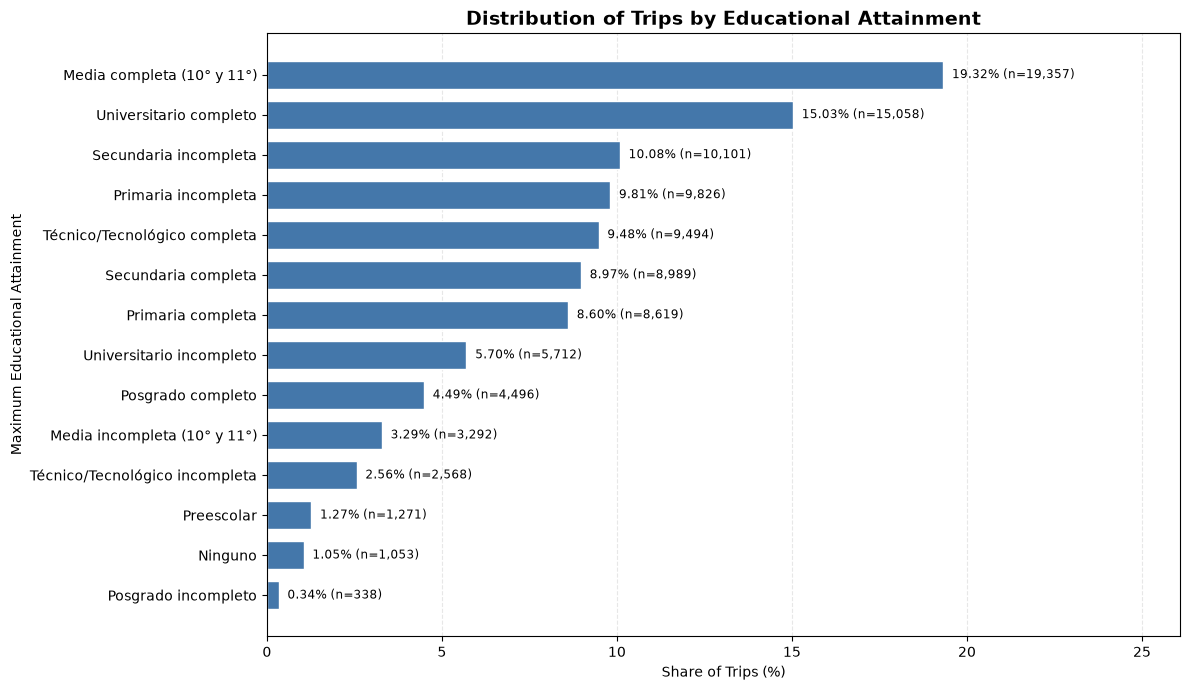

In [93]:

import matplotlib.pyplot as plt

# Sort education categories by frequency
education_plot = education_summary.sort_values(
    "percentage",
    ascending=True
)

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    education_plot.index,
    education_plot["percentage"],
    color="#4477AA",
    edgecolor="white",
    height=0.7
)

# Add percentage and count labels
for bar, row in zip(bars, education_plot.itertuples()):
    ax.text(
        bar.get_width() + 0.25,
        bar.get_y() + bar.get_height() / 2,
        f"{row.percentage:.2f}% (n={row.trip_count:,})",
        va="center",
        fontsize=8.5
    )

ax.set_title(
    "Distribution of Trips by Educational Attainment",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Share of Trips (%)")
ax.set_ylabel("Maximum Educational Attainment")

ax.set_xlim(0, education_plot["percentage"].max() * 1.35)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


In [94]:
# Educational attainment by age group

education_by_age = pd.crosstab(
    age_groups,
    df["max_nivel_edu"],
    normalize="index"
) * 100

display(education_by_age.round(1))

max_nivel_edu,Media completa (10° y 11°),Media incompleta (10° y 11°),Ninguno,Posgrado completo,Posgrado incompleto,Preescolar,Primaria completa,Primaria incompleta,Secundaria completa,Secundaria incompleta,Técnico/Tecnológico completa,Técnico/Tecnológico incompleta,Universitario completo,Universitario incompleto
edad,,,,,,,,,,,,,,
5-11,0.0,0.0,1.2,0.0,0.0,15.5,3.8,71.4,0.0,8.1,0.0,0.0,0.0,0.0
12-17,4.1,21.4,0.4,0.0,0.0,0.0,2.0,2.6,5.6,60.5,0.1,1.2,0.0,2.1
18-24,26.6,3.9,0.4,0.2,0.4,0.0,1.4,0.4,10.6,4.7,9.0,7.2,6.1,29.1
25-34,26.6,1.7,0.6,4.1,0.9,0.0,2.8,0.9,10.4,4.9,14.9,3.4,23.0,5.7
35-44,25.6,1.6,0.7,7.8,0.4,0.0,6.2,2.0,10.8,4.4,15.0,2.3,21.8,1.6
45-54,21.2,1.6,0.8,8.6,0.2,0.1,11.9,4.4,11.3,6.6,11.2,1.7,19.0,1.3
55-64,18.6,2.1,1.3,5.9,0.1,0.0,17.6,7.7,10.1,8.3,8.4,1.7,17.2,1.1
65-74,14.4,1.5,1.9,5.1,0.1,0.2,21.9,13.7,7.2,8.4,6.3,1.1,16.7,1.6
75+,9.7,1.4,6.3,4.6,0.3,0.4,23.5,21.7,6.2,4.3,4.4,0.7,15.2,1.2


##### 2.6.5	ocupacion_principal

In [95]:
occupation_summary = (
    df["ocupacion_principal"]
    .value_counts(dropna=False)
    .to_frame("trip_count")
)

occupation_summary["percentage"] = (
    occupation_summary["trip_count"] / len(df) * 100
)

display(occupation_summary.round(2))

,trip_count,percentage
ocupacion_principal,,
Empleado de empresa particular,25362,25.32
Trabajador independiente,18486,18.45
Colegio o escuela,15125,15.10
Dedicado al hogar,12649,12.63
Jubilado/pensionado,6229,6.22
Profesional independiente,4275,4.27
Universidad – Pregrado,4136,4.13
Empleado público,2549,2.54
Buscar trabajo,1989,1.99


In [96]:
print("Number of unique categories:", df["ocupacion_principal"].nunique())
print("Missing values:", df["ocupacion_principal"].isna().sum())
print("Missing percentage:", round(df["ocupacion_principal"].isna().mean() * 100, 2), "%")

Number of unique categories: 24
Missing values: 0
Missing percentage: 0.0 %


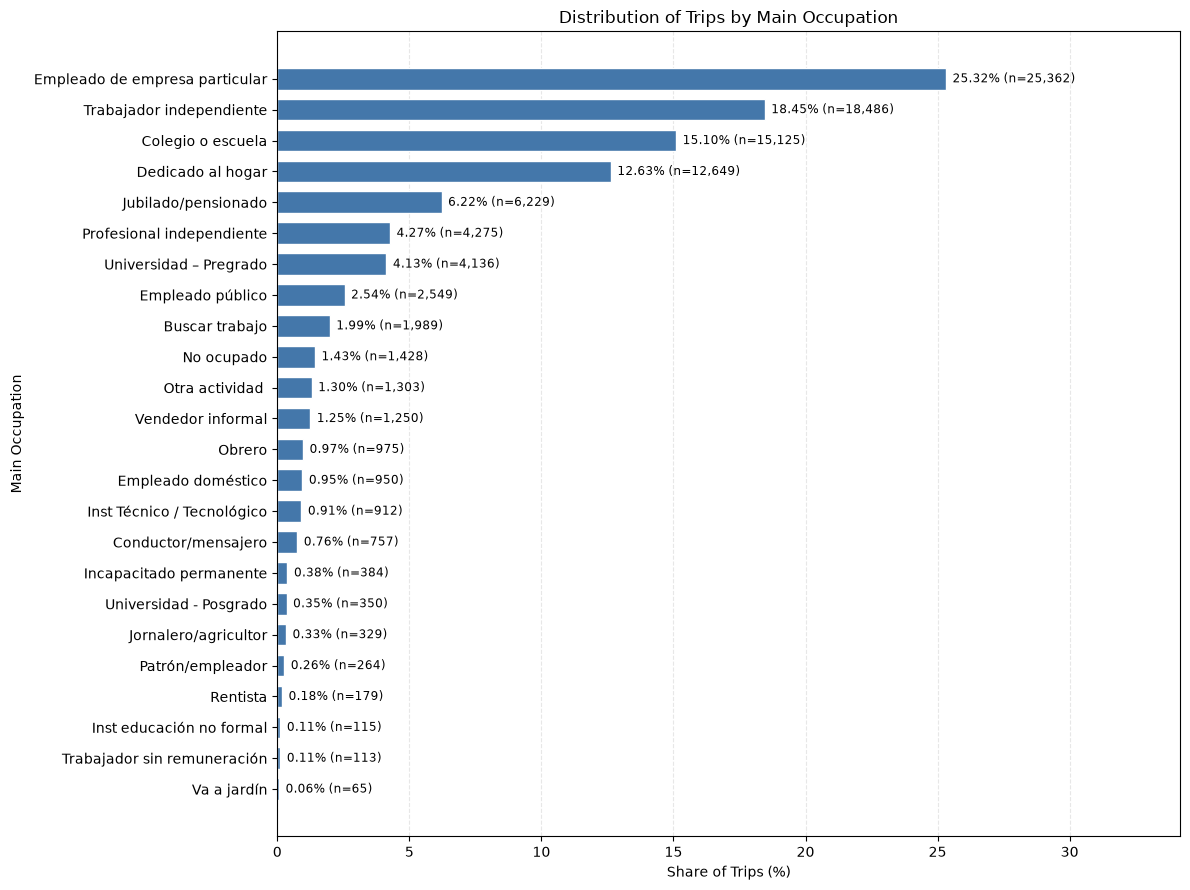

In [97]:
occupation_plot = occupation_summary.sort_values(
    "percentage", ascending=True
)

fig, ax = plt.subplots(figsize=(12, 9))

bars = ax.barh(
    occupation_plot.index,
    occupation_plot["percentage"],
    color="#4477AA",
    edgecolor="white",
    height=0.7
)

for bar, row in zip(bars, occupation_plot.itertuples()):
    ax.text(
        bar.get_width() + 0.25,
        bar.get_y() + bar.get_height() / 2,
        f"{row.percentage:.2f}% (n={row.trip_count:,})",
        va="center",
        fontsize=8.5
    )

ax.set_title("Distribution of Trips by Main Occupation")
ax.set_xlabel("Share of Trips (%)")
ax.set_ylabel("Main Occupation")

ax.set_xlim(0, occupation_plot["percentage"].max() * 1.35)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [98]:
occupation_by_age = pd.crosstab(
    age_groups,
    df["ocupacion_principal"],
    normalize="index"
) * 100

display(occupation_by_age.round(1))

ocupacion_principal,Buscar trabajo,Colegio o escuela,Conductor/mensajero,Dedicado al hogar,Empleado de empresa particular,Empleado doméstico,Empleado público,Incapacitado permanente,Inst Técnico / Tecnológico,Inst educación no formal,...,Otra actividad,Patrón/empleador,Profesional independiente,Rentista,Trabajador independiente,Trabajador sin remuneración,Universidad - Posgrado,Universidad – Pregrado,Va a jardín,Vendedor informal
edad,,,,,,,,,,,,,,,,,,,,,
5-11,0.0,96.6,0.0,0.0,0.0,0.0,0.0,0.1,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.8,0.0
12-17,0.2,91.5,0.0,0.8,0.5,0.0,0.0,0.1,1.2,0.4,...,0.8,0.0,0.1,0.0,0.6,0.1,0.1,2.2,0.0,0.1
18-24,3.9,5.3,0.5,4.8,32.0,0.4,1.2,0.1,5.1,0.5,...,1.9,0.0,1.1,0.0,12.0,0.1,1.1,26.4,0.0,1.1
25-34,3.1,0.3,1.0,8.9,47.3,1.0,3.7,0.2,0.6,0.1,...,1.1,0.2,4.9,0.0,19.9,0.1,0.9,2.7,0.0,1.6
35-44,2.1,0.1,1.0,9.5,41.1,1.8,4.7,0.3,0.2,0.0,...,1.2,0.4,6.9,0.1,26.0,0.1,0.2,0.2,0.0,1.5
45-54,2.1,0.1,1.3,14.6,29.7,1.6,4.2,0.5,0.1,0.0,...,1.1,0.7,8.2,0.2,29.6,0.2,0.1,0.1,0.0,1.7
55-64,1.8,0.1,0.9,23.9,15.0,1.4,2.8,0.6,0.1,0.0,...,1.5,0.5,6.2,0.4,27.9,0.2,0.0,0.0,0.0,1.8
65-74,0.7,0.0,0.5,30.9,2.7,0.4,0.6,0.8,0.0,0.0,...,1.5,0.2,2.7,0.5,17.3,0.2,0.0,0.0,0.0,1.4
75+,0.1,0.0,0.1,35.6,0.6,0.1,0.2,1.9,0.0,0.0,...,1.7,0.1,1.0,1.4,6.3,0.0,0.0,0.1,0.0,0.6


In [99]:
occupation_mode = pd.crosstab(
    df["ocupacion_principal"],
    df["modo_principal_agrupado"]
)

display(occupation_mode)

modo_principal_agrupado,A PIE <15 MIN,A PIE > 15 MIN,AUTO,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
ocupacion_principal,,,,,,,,,,,
Buscar trabajo,248,612,125,119,9,15,84,2,37,1,737
Colegio o escuela,3193,6691,562,523,210,144,170,3,143,1941,1545
Conductor/mensajero,61,83,179,39,19,17,122,41,42,12,142
Dedicado al hogar,2756,4892,831,195,126,138,107,11,573,4,3016
Empleado de empresa particular,1491,3066,3030,2433,979,168,3185,75,496,24,10415
Empleado doméstico,77,171,79,50,5,12,14,3,23,0,516
Empleado público,173,281,676,146,54,8,239,9,125,4,834
Incapacitado permanente,44,92,34,13,22,1,2,19,59,0,98
Inst Técnico / Tecnológico,28,138,32,63,10,16,31,2,10,6,576


In [100]:
occupation_mode_pct = pd.crosstab(
    df["ocupacion_principal"],
    df["modo_principal_agrupado"],
    normalize="index"
) * 100

display(occupation_mode_pct.round(1))

modo_principal_agrupado,A PIE <15 MIN,A PIE > 15 MIN,AUTO,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
ocupacion_principal,,,,,,,,,,,
Buscar trabajo,12.5,30.8,6.3,6.0,0.5,0.8,4.2,0.1,1.9,0.1,37.1
Colegio o escuela,21.1,44.2,3.7,3.5,1.4,1.0,1.1,0.0,0.9,12.8,10.2
Conductor/mensajero,8.1,11.0,23.6,5.2,2.5,2.2,16.1,5.4,5.5,1.6,18.8
Dedicado al hogar,21.8,38.7,6.6,1.5,1.0,1.1,0.8,0.1,4.5,0.0,23.8
Empleado de empresa particular,5.9,12.1,11.9,9.6,3.9,0.7,12.6,0.3,2.0,0.1,41.1
Empleado doméstico,8.1,18.0,8.3,5.3,0.5,1.3,1.5,0.3,2.4,0.0,54.3
Empleado público,6.8,11.0,26.5,5.7,2.1,0.3,9.4,0.4,4.9,0.2,32.7
Incapacitado permanente,11.5,24.0,8.9,3.4,5.7,0.3,0.5,4.9,15.4,0.0,25.5
Inst Técnico / Tecnológico,3.1,15.1,3.5,6.9,1.1,1.8,3.4,0.2,1.1,0.7,63.2


In [101]:
occupation_mode_counts = pd.crosstab(
    df["ocupacion_principal"],
    df["modo_principal_agrupado"]
)

print("Minimum cell count:", occupation_mode_counts.min().min())
print("Number of zero cells:", (occupation_mode_counts == 0).sum().sum())
print("Number of cells below 5:", (occupation_mode_counts < 5).sum().sum())
print("Number of cells below 10:", (occupation_mode_counts < 10).sum().sum())

Minimum cell count: 0
Number of zero cells: 18
Number of cells below 5: 55
Number of cells below 10: 73


In [102]:
small_cells = occupation_mode_counts.stack().reset_index()

small_cells.columns = [
    "occupation",
    "travel_mode",
    "trip_count"
]

small_cells = small_cells[
    small_cells["trip_count"] < 10
].sort_values("trip_count")


display(small_cells)

,occupation,travel_mode,trip_count
192,Rentista,INFORMAL,0
248,Va a jardín,MOTO,0
119,Jornalero/agricultor,TRANSPORTE ESCOLAR,0
152,Obrero,TRANSPORTE ESCOLAR,0
260,Vendedor informal,OTRO,0
...,...,...,...
238,Universidad – Pregrado,OTRO,8
151,Obrero,TAXI OCUPADO,9
101,Inst educación no formal,AUTO,9
73,Empleado público,OTRO,9


In [103]:
occupation_diagnostics = pd.DataFrame({
    "total_trips": occupation_mode_counts.sum(axis=1),
    "zero_cells": (occupation_mode_counts == 0).sum(axis=1),
    "cells_below_5": (occupation_mode_counts < 5).sum(axis=1),
    "cells_below_10": (occupation_mode_counts < 10).sum(axis=1)
})

occupation_diagnostics = occupation_diagnostics.sort_values(
    ["total_trips", "cells_below_10"]
)

display(occupation_diagnostics)

,total_trips,zero_cells,cells_below_5,cells_below_10
ocupacion_principal,,,,
Va a jardín,65,2,7,8
Trabajador sin remuneración,113,2,7,8
Inst educación no formal,115,1,6,8
Rentista,179,4,5,5
Patrón/empleador,264,1,3,5
Jornalero/agricultor,329,1,4,4
Universidad - Posgrado,350,2,4,4
Incapacitado permanente,384,1,3,3
Conductor/mensajero,757,0,0,0


In [104]:
occupation_diagnostics["share_cells_below_10"] = (
    occupation_diagnostics["cells_below_10"] / 11 * 100
)

display(
    occupation_diagnostics[
        occupation_diagnostics["total_trips"] < 1000
    ].round(2)
)

,total_trips,zero_cells,cells_below_5,cells_below_10,share_cells_below_10
ocupacion_principal,,,,,
Va a jardín,65,2,7,8,72.73
Trabajador sin remuneración,113,2,7,8,72.73
Inst educación no formal,115,1,6,8,72.73
Rentista,179,4,5,5,45.45
Patrón/empleador,264,1,3,5,45.45
Jornalero/agricultor,329,1,4,4,36.36
Universidad - Posgrado,350,2,4,4,36.36
Incapacitado permanente,384,1,3,3,27.27
Conductor/mensajero,757,0,0,0,0.00


** Occupation – EDA conclusions and pending decisions

The occupation variable contains 24 categories with no missing values. Its relationship with travel mode reveals meaningful behavioral differences across occupations.

The occupation–mode cross-tabulation identifies 18 zero-frequency cells, 55 cells with fewer than 5 trips, and 73 with fewer than 10 trips (out of 264 possible combinations).

**Main conclusion:** Low-frequency categories should not be automatically removed or grouped. Some, such as drivers/messengers and agricultural workers, show potentially distinctive modal patterns.

**Decision:** Retain all 24 original categories for now.

**Pending tasks:**
- Review official occupation definitions.
- Evaluate conceptually justified groupings, particularly educational categories.
- Assess sparse categories and their implications for MNL estimation.
- Create an alternative grouped variable without modifying the original.
- Compare model stability and predictive performance using both classifications.

##### 2.6.6	estra_hg

In [105]:
strata_summary = (
    df["estra_hg"]
    .value_counts(dropna=False)
    .to_frame("trip_count")
)

strata_summary["percentage"] = (
    strata_summary["trip_count"] / len(df) * 100
)

display(strata_summary.round(2))

,trip_count,percentage
estra_hg,,
2,25682,25.64
3,23373,23.33
No aplica,22511,22.47
1,13942,13.92
4,7390,7.38
5,4217,4.21
6,3059,3.05


In [108]:
strata_mode_counts = pd.crosstab(
    df["estra_hg"],
    df["modo_principal_agrupado"]
)

display(strata_mode_counts)

modo_principal_agrupado,A PIE <15 MIN,A PIE > 15 MIN,AUTO,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
estra_hg,,,,,,,,,,,
1,1360,3786,443,464,78,207,952,41,214,333,6064
2,3284,6894,1255,1716,287,210,1803,75,743,396,9019
3,3017,5671,2852,1426,324,84,1441,72,1002,374,7110
4,696,1321,2058,296,206,12,306,31,556,263,1645
5,316,711,1784,103,119,1,123,30,317,169,544
6,176,349,1737,86,84,3,155,7,244,101,117
No aplica,3543,6200,2457,2013,884,350,1467,76,191,422,4908


In [118]:
strata_age_pct = pd.crosstab(
     age_groups,
     df["estra_hg"],
     normalize="index"
 ) * 100

display(strata_age_pct.round(1))

estra_hg,1,2,3,4,5,6,No aplica
edad,,,,,,,
5-11,20.6,28.9,16.5,3.1,1.8,1.3,27.9
12-17,19.4,28.0,19.0,4.2,2.0,1.4,26.0
18-24,14.4,25.8,22.9,6.0,3.3,3.1,24.5
25-34,15.2,26.5,22.4,6.1,3.6,2.5,23.7
35-44,13.6,24.3,24.6,7.8,4.1,3.4,22.1
45-54,11.2,25.1,24.8,9.1,5.3,4.0,20.5
55-64,11.5,25.4,25.3,9.2,4.9,3.2,20.5
65-74,10.1,24.7,26.2,10.7,6.4,4.4,17.3
75+,8.6,19.4,29.4,11.8,8.8,4.2,17.8


In [110]:
strata_occupation_pct = pd.crosstab(
    df["ocupacion_principal"],
    df["estra_hg"],
    normalize="index"
) * 100

display(strata_occupation_pct.round(1))

estra_hg,1,2,3,4,5,6,No aplica
ocupacion_principal,,,,,,,
Buscar trabajo,23.2,30.7,20.9,3.1,1.0,0.4,20.8
Colegio o escuela,19.7,28.0,18.1,3.6,2.0,1.3,27.2
Conductor/mensajero,14.3,28.1,26.6,1.3,0.1,1.6,28.0
Dedicado al hogar,17.2,29.4,20.7,4.9,2.5,1.2,24.2
Empleado de empresa particular,12.2,26.0,23.8,7.6,3.7,2.8,23.9
Empleado doméstico,27.7,23.4,14.9,4.0,2.1,8.2,19.7
Empleado público,5.4,15.9,28.4,17.6,9.7,4.2,18.8
Incapacitado permanente,23.2,34.1,16.1,6.8,3.6,1.6,14.6
Inst Técnico / Tecnológico,17.7,28.6,23.1,3.1,0.9,0.9,25.8


2.6.6 Household Socioeconomic Stratum (`estra_hg`) — EDA Conclusions

**Main finding:** Household socioeconomic stratum exhibits a strong descriptive association with travel mode choice. Auto use increases substantially from lower to higher strata, while public transport use decreases. Walking also tends to decline, whereas bicycle use does not follow a clear monotonic pattern.

Age and occupation cross-tabulations reveal additional socioeconomic differences. The high proportion of `No aplica` among some occupations, particularly agricultural workers, requires validation against the official survey definitions.

**Decisions:**
- Retain `estra_hg` as a priority explanatory variable.
- Preserve strata 1–6 separately.
- Keep `No aplica` as a separate category pending validation.
- Treat the variable as categorical in initial model specifications.

**Pending:**
- Validate the meaning and eligibility rules of `No aplica`.
- Repeat descriptive comparisons using trip expansion weights (`fexp_vj`), after validating their interpretation.
- Evaluate interactions or heterogeneous modal patterns across socioeconomic strata.
- Examine associations with household vehicle availability and geographic location.
- Assess potential overlap with age and occupation during model diagnostics.

##### 2.6.7	hogar__ingre_mes_hg

In [112]:
df["hogar__ingre_mes_hg"].value_counts(dropna=False).head(20)

hogar__ingre_mes_hg
NS/NR              20892
1160001-1500000    12435
1500001-2000000    11658
2000001-2500000    11354
800001-1160000     11036
2500001-3500000    10545
3500001-4900000     7357
400001-800000       4359
4900001-6800000     4333
6800001-9000000     2275
>9000000            1993
0-400000            1937
Name: count, dtype: int64

In [120]:
income_mode_pct = pd.crosstab(
    df["hogar__ingre_mes_hg"],
    df["modo_principal_agrupado"],
    normalize="index"
) * 100

income_mode_pct.round(2)

modo_principal_agrupado,A PIE <15 MIN,A PIE > 15 MIN,AUTO,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
hogar__ingre_mes_hg,,,,,,,,,,,
0-400000,16.11,39.96,2.37,4.34,0.98,1.60,1.24,0.46,2.58,1.55,28.81
1160001-1500000,13.82,27.33,5.15,7.00,1.66,1.32,6.18,0.28,2.05,1.46,33.74
1500001-2000000,12.03,25.68,5.88,7.28,1.93,1.21,7.75,0.19,2.45,2.25,33.35
2000001-2500000,11.83,24.82,6.96,6.35,1.69,0.78,7.87,0.33,2.62,1.71,35.06
2500001-3500000,10.47,21.80,10.91,6.28,2.42,0.65,7.81,0.34,3.33,2.13,33.85
3500001-4900000,10.32,17.81,20.10,5.07,2.72,0.64,7.90,0.37,4.17,2.27,28.64
400001-800000,13.58,35.24,3.05,5.30,1.12,1.49,2.16,0.28,2.02,1.35,34.41
4900001-6800000,7.29,17.17,30.23,4.32,2.79,0.39,5.82,0.72,5.08,3.25,22.94
6800001-9000000,7.87,13.45,38.15,2.33,3.03,0.79,5.23,0.53,6.68,4.09,17.85


In [121]:
income_mode_pct[
    ["AUTO", "TRANSPORTE PÚBLICO", "A PIE > 15 MIN", "MOTO"]
].round(2)

modo_principal_agrupado,AUTO,TRANSPORTE PÚBLICO,A PIE > 15 MIN,MOTO
hogar__ingre_mes_hg,,,,
0-400000,2.37,28.81,39.96,1.24
1160001-1500000,5.15,33.74,27.33,6.18
1500001-2000000,5.88,33.35,25.68,7.75
2000001-2500000,6.96,35.06,24.82,7.87
2500001-3500000,10.91,33.85,21.80,7.81
3500001-4900000,20.10,28.64,17.81,7.90
400001-800000,3.05,34.41,35.24,2.16
4900001-6800000,30.23,22.94,17.17,5.82
6800001-9000000,38.15,17.85,13.45,5.23


<Axes: xlabel='hogar__ingre_mes_hg'>

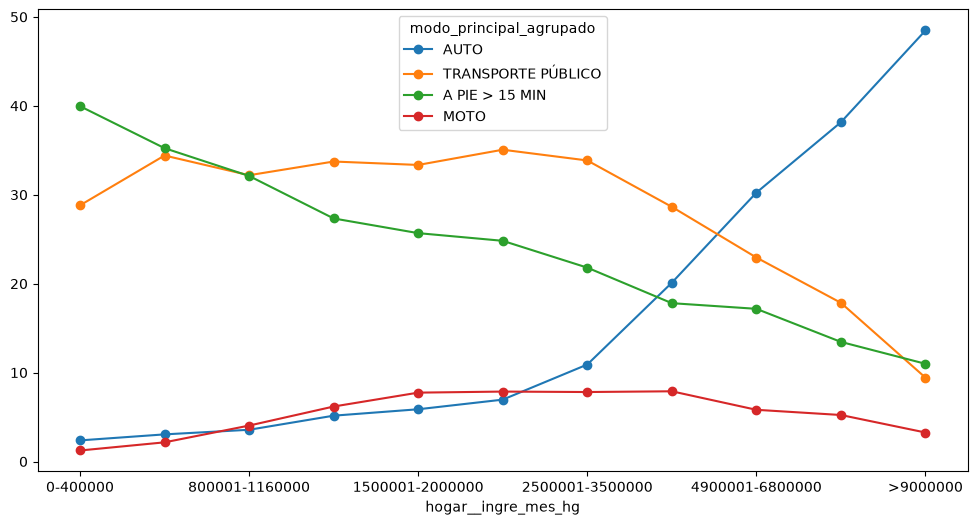

In [122]:
income_order = [
    "0-400000",
    "400001-800000",
    "800001-1160000",
    "1160001-1500000",
    "1500001-2000000",
    "2000001-2500000",
    "2500001-3500000",
    "3500001-4900000",
    "4900001-6800000",
    "6800001-9000000",
    ">9000000"
]

income_trend = income_mode_pct.loc[income_order]

income_trend[
    ["AUTO", "TRANSPORTE PÚBLICO", "A PIE > 15 MIN", "MOTO"]
].plot(
    marker="o",
    figsize=(12, 6)
)

In [123]:
income_stratum_counts = pd.crosstab(
    df["hogar__ingre_mes_hg"],
    df["estra_hg"]
)

income_stratum_counts

estra_hg,1,2,3,4,5,6,No aplica
hogar__ingre_mes_hg,,,,,,,
0-400000,678,696,196,16,3,0,348
1160001-1500000,2699,3860,2195,152,58,18,3453
1500001-2000000,2092,3693,2425,367,57,10,3014
2000001-2500000,1656,3194,2746,420,83,36,3219
2500001-3500000,747,2780,3451,669,152,54,2692
3500001-4900000,315,1426,2472,850,496,208,1590
400001-800000,1406,1655,556,47,8,0,687
4900001-6800000,137,421,1310,789,765,328,583
6800001-9000000,19,107,493,548,646,256,206


In [124]:
income_stratum_pct = pd.crosstab(
    df["hogar__ingre_mes_hg"],
    df["estra_hg"],
    normalize="index"
) * 100

income_stratum_pct.round(2)

estra_hg,1,2,3,4,5,6,No aplica
hogar__ingre_mes_hg,,,,,,,
0-400000,35.00,35.93,10.12,0.83,0.15,0.00,17.97
1160001-1500000,21.70,31.04,17.65,1.22,0.47,0.14,27.77
1500001-2000000,17.94,31.68,20.80,3.15,0.49,0.09,25.85
2000001-2500000,14.59,28.13,24.19,3.70,0.73,0.32,28.35
2500001-3500000,7.08,26.36,32.73,6.34,1.44,0.51,25.53
3500001-4900000,4.28,19.38,33.60,11.55,6.74,2.83,21.61
400001-800000,32.26,37.97,12.76,1.08,0.18,0.00,15.76
4900001-6800000,3.16,9.72,30.23,18.21,17.66,7.57,13.45
6800001-9000000,0.84,4.70,21.67,24.09,28.40,11.25,9.05


In [125]:
income_order = [
    "0-400000",
    "400001-800000",
    "800001-1160000",
    "1160001-1500000",
    "1500001-2000000",
    "2000001-2500000",
    "2500001-3500000",
    "3500001-4900000",
    "4900001-6800000",
    "6800001-9000000",
    ">9000000",
    "NS/NR"
]

stratum_order = [
    "1", "2", "3", "4", "5", "6", "No aplica"
]

income_stratum_pct = income_stratum_pct.reindex(
    index=income_order,
    columns=stratum_order
)

income_stratum_pct.round(2)

estra_hg,1,2,3,4,5,6,No aplica
hogar__ingre_mes_hg,,,,,,,
0-400000,35.00,35.93,10.12,0.83,0.15,0.00,17.97
400001-800000,32.26,37.97,12.76,1.08,0.18,0.00,15.76
800001-1160000,25.70,34.16,14.55,0.92,0.45,0.18,24.04
1160001-1500000,21.70,31.04,17.65,1.22,0.47,0.14,27.77
1500001-2000000,17.94,31.68,20.80,3.15,0.49,0.09,25.85
2000001-2500000,14.59,28.13,24.19,3.70,0.73,0.32,28.35
2500001-3500000,7.08,26.36,32.73,6.34,1.44,0.51,25.53
3500001-4900000,4.28,19.38,33.60,11.55,6.74,2.83,21.61
4900001-6800000,3.16,9.72,30.23,18.21,17.66,7.57,13.45


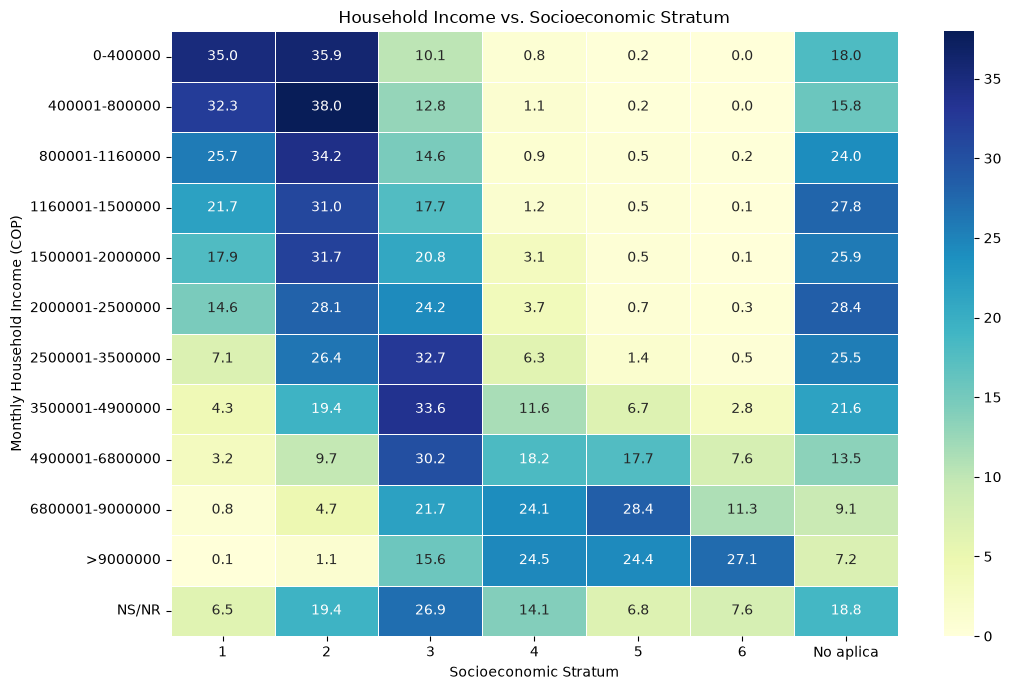

In [129]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 7))

sns.heatmap(
    income_stratum_pct,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Household Income vs. Socioeconomic Stratum")
plt.xlabel("Socioeconomic Stratum")
plt.ylabel("Monthly Household Income (COP)")

plt.tight_layout()
plt.show()

2.6.7.2 Income vs. Socioeconomic Stratum — Conclusions

Household income and socioeconomic stratum exhibit a clear positive association, but they are not interchangeable. Lower-income households are concentrated in strata 1–2, while higher-income households increasingly belong to strata 4–6.

The results also reveal substantial income variation within socioeconomic strata, suggesting that both variables may provide complementary information.

**Decisions:**
- Retain both variables as candidate predictors.
- Preserve the original income categories and strata.
- Keep `NS/NR` and `No aplica` as separate categories pending validation.
- Compare model specifications using income, stratum, and both variables jointly.


In [130]:
df["vehicle_records_in_household"].value_counts().sort_index()

vehicle_records_in_household
0     39911
1     40053
2     14981
3      3869
4       930
5       286
6       122
7        18
10        4
Name: count, dtype: int64

In [131]:
income_vehicle = pd.crosstab(
    df["hogar__ingre_mes_hg"],
    df["vehicle_records_in_household"],
    normalize="index"
) * 100

income_vehicle.round(2)

vehicle_records_in_household,0,1,2,3,4,5,6,7,10
hogar__ingre_mes_hg,,,,,,,,,
0-400000,77.03,20.70,2.27,0.00,0.00,0.00,0.00,0.00,0.00
1160001-1500000,50.69,40.10,8.20,1.00,0.02,0.00,0.00,0.00,0.00
1500001-2000000,44.20,42.68,10.90,1.80,0.29,0.00,0.12,0.00,0.00
2000001-2500000,40.01,43.37,13.12,3.07,0.30,0.05,0.07,0.00,0.00
2500001-3500000,35.60,41.69,17.25,4.28,0.93,0.18,0.04,0.00,0.04
3500001-4900000,24.19,42.64,24.74,6.51,1.52,0.39,0.00,0.00,0.00
400001-800000,71.35,25.58,2.66,0.28,0.14,0.00,0.00,0.00,0.00
4900001-6800000,15.74,45.42,26.56,8.95,2.10,0.85,0.37,0.00,0.00
6800001-9000000,9.93,46.81,28.57,9.67,3.34,1.05,0.62,0.00,0.00


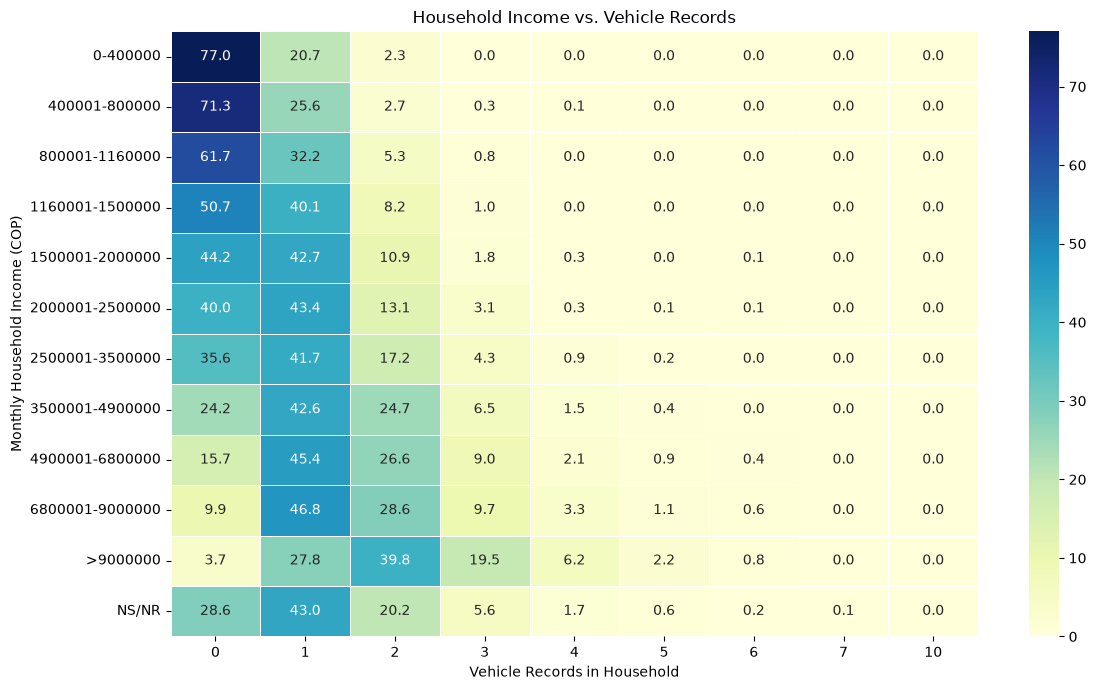

In [132]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    income_vehicle.reindex(income_order),
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Household Income vs. Vehicle Records")
plt.xlabel("Vehicle Records in Household")
plt.ylabel("Monthly Household Income (COP)")

plt.tight_layout()
plt.show()

2.6.7.3 Income vs. Household Vehicle Records — Conclusions

Household income exhibits a strong positive association with the number of vehicle records linked to the household. The share of trips from households with zero vehicle records decreases from 77.03% in the lowest income group to 3.71% in the highest. Conversely, households with two or more records account for 68.44% of trips in the highest income group.

These findings complement the observed income-related differences in travel mode choice, particularly automobile use.

**Decisions:**
- Retain household income and vehicle records as candidate predictors.
- Preserve the original vehicle-record count.
- Use the 2+ grouping only for descriptive comparisons.
- Avoid interpreting vehicle records as confirmed individual vehicle availability.

**Pending:** Validate the meaning of vehicle records and evaluate the joint contribution of income, socioeconomic stratum, and household vehicle records during modeling.

In [133]:
df["fexp_vj"].dtype

dtype('float64')

In [134]:
df["fexp_vj"].head(15)

0     274.9
1     274.9
2     274.9
3     274.9
4     274.9
5     274.9
6     274.9
7     274.9
8     274.9
9     274.9
10     71.9
11     71.9
12     71.9
13     71.9
14     71.9
Name: fexp_vj, dtype: float64

In [136]:
df["fexp_vj"].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])

count    100174.000000
mean        166.939957
std         168.891412
min           1.500000
1%            1.900000
5%            5.200000
25%          47.100000
50%         123.700000
75%         230.600000
95%         495.300000
99%         797.400000
max        1741.100000
Name: fexp_vj, dtype: float64

In [137]:
df["fexp_vj"].nunique()

4782

In [138]:
df["fexp_vj"].sum()

np.float64(16723043.3)

In [139]:
income_mode_weighted = df.pivot_table(
    index="hogar__ingre_mes_hg",
    columns="modo_principal_agrupado",
    values="fexp_vj",
    aggfunc="sum",
    observed=False
)

In [140]:
income_mode_weighted_pct = (
    income_mode_weighted
    .div(income_mode_weighted.sum(axis=1), axis=0)
    * 100
)

In [141]:
income_mode_weighted_pct.loc[
    income_order,
    ["AUTO", "TRANSPORTE PÚBLICO", "A PIE > 15 MIN", "MOTO"]
].round(2)

modo_principal_agrupado,AUTO,TRANSPORTE PÚBLICO,A PIE > 15 MIN,MOTO
hogar__ingre_mes_hg,,,,
0-400000,1.23,21.80,40.85,1.88
400001-800000,3.26,30.02,35.16,1.66
800001-1160000,3.50,30.11,31.38,3.84
1160001-1500000,6.23,31.71,26.06,6.95
1500001-2000000,6.32,33.29,24.58,7.44
2000001-2500000,7.42,34.78,24.26,8.20
2500001-3500000,10.95,35.10,19.25,9.00
3500001-4900000,19.61,31.52,16.01,9.05
4900001-6800000,28.81,28.02,16.97,5.92


2.6.7.4 Weighted Analysis — Conclusions

The expansion-weighted results preserve the main patterns observed in the unweighted analysis.

Automobile use increases substantially with household income, while public transport and walking generally decline at higher income levels. Motorcycle use follows a different, non-monotonic pattern.

Although weighting changes some modal shares, particularly in lower and intermediate income groups, the overall socioeconomic gradient remains consistent.

**Decisions:**
- Retain household income as a priority candidate predictor.
- Use `fexp_vj` for weighted descriptive analysis.
- Report weighted and unweighted distributions where relevant.
- Preserve `NS/NR` as a separate income category.

**Methodological note:** These are weighted descriptive estimates. Further validation of the survey sampling design is required before conducting population-level statistical inference.

In [142]:
weight_by_person = (
    df.groupby("key_pers")["fexp_vj"]
    .nunique()
)

weight_by_person.value_counts()

fexp_vj
1    48539
Name: count, dtype: int64

In [143]:
weight_by_household = (
    df.groupby("key_hg")["fexp_vj"]
    .nunique()
)

weight_by_household.value_counts()

fexp_vj
1    21508
Name: count, dtype: int64

**Expansion Factor (`fexp_vj`) – Preliminary Assessment**

The expansion factor is constant across all trips associated with the same individual and household. It is retained as an auxiliary weighting variable.

Weighted descriptive statistics may be explored alongside unweighted results. However, its operational definition and population-level interpretation remain subject to methodological validation.

**Decision:** Retain `fexp_vj`; no further investigation at this EDA stage.

##### 2.6.8 – Valid Driver's License

In [145]:
df["persona__licencia_cond_vigente"].value_counts(dropna=False)

persona__licencia_cond_vigente
No tiene                           57316
Vehículo particular                18272
No aplica                          12914
Moto                                5230
Vehículo particular/moto            4141
Vehículo parti./transp. público     1008
Transporte público                   639
Todas las anteriores                 608
Transporte público/moto               46
Name: count, dtype: int64

In [146]:
license_summary = (
    df["persona__licencia_cond_vigente"]
    .value_counts(dropna=False)
    .to_frame("trip_count")
)

license_summary["percentage"] = (
    license_summary["trip_count"] / len(df) * 100
)

license_summary.round(2)

,trip_count,percentage
persona__licencia_cond_vigente,,
No tiene,57316,57.22
Vehículo particular,18272,18.24
No aplica,12914,12.89
Moto,5230,5.22
Vehículo particular/moto,4141,4.13
Vehículo parti./transp. público,1008,1.01
Transporte público,639,0.64
Todas las anteriores,608,0.61
Transporte público/moto,46,0.05


In [147]:
license_mode = pd.crosstab(
    df["persona__licencia_cond_vigente"],
    df["modo_principal_agrupado"],
    normalize="index"
) * 100

license_mode.round(2)

modo_principal_agrupado,A PIE <15 MIN,A PIE > 15 MIN,AUTO,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
persona__licencia_cond_vigente,,,,,,,,,,,
Moto,4.24,6.73,2.28,4.93,0.90,0.46,66.21,0.08,0.96,0.00,13.21
No aplica,22.09,44.90,3.96,2.96,1.49,0.90,1.05,0.02,0.82,13.74,8.05
No tiene,13.08,26.94,3.98,7.47,2.13,1.11,1.19,0.21,3.51,0.40,39.98
Todas las anteriores,7.24,8.55,25.16,7.07,2.96,0.82,28.45,2.30,1.32,0.66,15.46
Transporte público,10.02,14.08,15.96,4.23,2.19,1.25,4.23,7.82,8.14,0.63,31.46
Transporte público/moto,2.17,8.70,10.87,4.35,0.00,0.00,39.13,0.00,6.52,0.00,28.26
Vehículo parti./transp. público,8.73,14.68,35.91,5.36,3.17,1.19,1.29,2.98,4.96,0.99,20.73
Vehículo particular,7.54,14.58,43.27,4.64,2.19,0.25,1.34,0.49,5.06,0.19,20.46
Vehículo particular/moto,5.96,9.27,27.63,5.05,1.45,0.41,35.96,0.53,1.55,0.00,12.20


2.6.8 Valid Driver's License — Conclusions

The driver's license variable exhibits a clear association with travel mode choice. Individuals reporting a private vehicle license show a higher share of automobile trips, while those reporting a motorcycle license predominantly use motorcycles.

**Decisions:**
- Retain the original license categories for now.
- Keep `No tiene` and `No aplica` separate.
- Consider the variable a candidate predictor of medium-high priority.
- Avoid interpreting license ownership as actual vehicle availability or use.

**Pending:** Validate the meaning of `No aplica` and assess whether some license categories can be conceptually grouped for modeling.

##### 2.6.9 – Household Type

In [148]:
df["hogar__tipo_viv"].value_counts(dropna=False)

hogar__tipo_viv
Casa                  59968
Apartamento           38605
Cuarto inquilinato     1315
Cuarto otro             265
Otro tipo                21
Name: count, dtype: int64

In [149]:
df["hogar__tipo_viv"].value_counts(
    normalize=True,
    dropna=False
).mul(100).round(2)

hogar__tipo_viv
Casa                  59.86
Apartamento           38.54
Cuarto inquilinato     1.31
Cuarto otro            0.26
Otro tipo              0.02
Name: proportion, dtype: float64

In [150]:
pd.crosstab(
    df["hogar__tipo_viv"],
    df["modo_principal_agrupado"],
    normalize="index"
).mul(100).round(2)

modo_principal_agrupado,A PIE <15 MIN,A PIE > 15 MIN,AUTO,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
hogar__tipo_viv,,,,,,,,,,,
Apartamento,12.18,23.40,16.24,5.79,2.12,0.54,5.63,0.37,4.04,2.52,27.18
Casa,12.30,25.50,10.47,6.25,1.92,1.09,6.69,0.32,2.82,1.80,30.84
Cuarto inquilinato,19.09,38.63,2.21,7.30,0.68,0.38,3.57,0.00,0.91,0.53,26.69
Cuarto otro,20.75,35.47,3.77,8.30,2.26,0.38,4.53,0.00,1.13,0.00,23.40
Otro tipo,19.05,38.10,0.00,4.76,0.00,0.00,0.00,0.00,0.00,0.00,38.10


**Household Type — EDA Conclusions**

Household type is predominantly represented by houses (59.86%) and apartments (38.54%). The observed travel mode distribution differs moderately across these categories, while smaller housing categories show less stable patterns due to their limited sample sizes.

**Decisions:**
- Retain `hogar__tipo_viv` as a candidate socioeconomic predictor.
- Preserve the original categories for now.
- Treat results for less frequent housing categories with caution.
- Avoid interpreting housing type as a direct measure of density, accessibility, or residential location.
- Assess its contribution alongside household income and socioeconomic stratum during model specification.

#### 2.7 Household Characteristics

##### 2.7.1 Household Size and Composition

In [157]:
household_size_variables = [
    "hogar__perstotal_hg",
    "hogar__pers>5años_hg",
    "hogar__pers>18años_hg"
]

household_size_summary = df[household_size_variables].describe(
    percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
)

display(household_size_summary.round(2))

,hogar__perstotal_hg,hogar__pers>5años_hg,hogar__pers>18años_hg
count,100174.00,100174.00,100174.00
mean,3.59,3.46,2.80
std,1.55,1.48,1.21
min,1.00,1.00,1.00
5%,1.00,1.00,1.00
25%,3.00,2.00,2.00
50%,3.00,3.00,3.00
75%,4.00,4.00,4.00
95%,6.00,6.00,5.00
max,11.00,11.00,10.00


In [158]:
for variable in household_size_variables:

    print(f"\n{variable}")

    display(
        df[variable]
        .value_counts()
        .sort_index()
        .rename_axis("household_size")
        .to_frame("trip_count")
    )


hogar__perstotal_hg


,trip_count
household_size,
1,6520
2,18273
3,25678
4,26209
5,13774
6,5399
7,2514
8,950
9,494



hogar__pers>5años_hg


,trip_count
household_size,
1,6824
2,20243
3,27141
4,25327
5,12539
6,4843
7,1893
8,846
9,275



hogar__pers>18años_hg


,trip_count
household_size,
1,10248
2,37231
3,27604
4,16683
5,5878
6,1698
7,549
8,214
9,39


**Household Size and Composition — EDA Conclusions**

Household size is concentrated around three to four members. The distributions of total household members and members older than five years are very similar, while the number of adults (older than 18 years) captures a distinct aspect of household composition.

**Preliminary decisions:**
- Retain `hogar__perstotal_hg` as the main household-size indicator.
- Retain `hogar__pers>18años_hg` as a candidate measure of household composition.
- Assign lower priority to `hogar__pers>5años_hg` due to its similar distribution to total household size.
- Reassess potential redundancy during multivariate analysis.

Counts represent trip observations, not unique households.

##### 2.7.2 Household Vehicle Records

In [159]:
vehicle_counts = (
    df["vehicle_records_in_household"]
    .value_counts(dropna=False)
    .sort_index()
)

vehicle_summary = pd.DataFrame({
    "trip_count": vehicle_counts,
    "percentage": vehicle_counts / len(df) * 100
})

display(vehicle_summary.round(2))

,trip_count,percentage
vehicle_records_in_household,,
0,39911,39.84
1,40053,39.98
2,14981,14.95
3,3869,3.86
4,930,0.93
5,286,0.29
6,122,0.12
7,18,0.02
10,4,0.00


In [160]:
vehicle_mode_distribution = pd.crosstab(
    df["vehicle_records_in_household"],
    df["modo_principal_agrupado"],
    normalize="index"
) * 100

display(vehicle_mode_distribution.round(2))

modo_principal_agrupado,A PIE <15 MIN,A PIE > 15 MIN,AUTO,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
vehicle_records_in_household,,,,,,,,,,,
0,13.80,32.43,1.38,1.60,2.08,1.15,0.30,0.14,3.74,1.56,41.82
1,11.90,22.22,16.00,9.85,1.95,0.69,8.31,0.35,3.06,2.12,23.55
2,11.01,16.18,26.35,8.02,1.76,0.69,12.64,0.52,2.74,2.64,17.46
3,10.05,13.52,28.95,6.82,2.33,0.28,16.77,1.19,2.56,3.18,14.34
4,6.67,10.22,36.77,5.48,0.97,1.61,20.00,0.11,3.55,4.84,9.78
5,3.85,8.39,53.50,1.40,2.45,0.00,15.38,3.85,1.40,5.59,4.20
6,4.10,18.03,39.34,1.64,0.00,1.64,20.49,0.00,3.28,4.92,6.56
7,0.00,0.00,88.89,0.00,0.00,0.00,0.00,0.00,0.00,11.11,0.00
10,0.00,0.00,50.00,0.00,0.00,0.00,50.00,0.00,0.00,0.00,0.00


In [161]:
vehicle_data = df[[
    "vehicle_records_in_household",
    "modo_principal_agrupado"
]].copy()

vehicle_data["vehicle_group"] = pd.cut(
    vehicle_data["vehicle_records_in_household"],
    bins=[-1, 0, 1, float("inf")],
    labels=["No records", "One record", "Two or more records"]
)

vehicle_group_mode = pd.crosstab(
    vehicle_data["vehicle_group"],
    vehicle_data["modo_principal_agrupado"],
    normalize="index"
) * 100

display(vehicle_group_mode.round(2))

modo_principal_agrupado,A PIE <15 MIN,A PIE > 15 MIN,AUTO,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
vehicle_group,,,,,,,,,,,
No records,13.80,32.43,1.38,1.60,2.08,1.15,0.30,0.14,3.74,1.56,41.82
One record,11.90,22.22,16.00,9.85,1.95,0.69,8.31,0.35,3.06,2.12,23.55
Two or more records,10.47,15.28,27.85,7.53,1.83,0.65,13.85,0.67,2.73,2.90,16.24


**Household Vehicle Records — EDA Conclusions**

Most trip observations are associated with households reporting zero or one vehicle record (79.82%). The distribution of travel modes varies substantially across vehicle-record categories.

As the number of household vehicle records increases:
- Auto mode share increases considerably.
- Public transport and walking shares decrease.
- Motorcycle mode share also increases.

**Preliminary decisions:**
- Retain `vehicle_records_in_household` as a high-priority candidate predictor.
- Preserve the original count variable.
- Consider a grouped specification (0, 1, 2+ records) for comparison.
- Interpret this variable as a proxy for household-level vehicle resources or potential availability, not confirmed individual vehicle access.
- Reassess its relationship with income, socioeconomic stratum, and household composition during multivariate analysis.

Results represent trip observations rather than unique households. Categories with very small sample sizes should be interpreted cautiously.

Variable	Decisión preliminar
hogar__perstotal_hg	Conservar
hogar__pers>18años_hg	Conservar como candidata
hogar__pers>5años_hg	Baja prioridad por posible redundancia
vehicle_records_in_household	Conservar, prioridad alta

#### 2.8 Travel Behavior Variables

##### 2.8.1 Travel Frequency

In [162]:
variable = "frecuencia_viaje"

frequency_summary = pd.DataFrame({
    "count": df[variable].value_counts(dropna=False),
    "percentage": df[variable].value_counts(
        normalize=True, dropna=False
    ) * 100
})

display(frequency_summary.round(2))

,count,percentage
frecuencia_viaje,,
Prácticamente todos los días,54941,54.85
Varias veces a la semana,23665,23.62
En algunas ocasiones al mes,17662,17.63
Esporádicamente en el año,3586,3.58
Nunca lo realizo,320,0.32


In [163]:
frequency_mode = pd.crosstab(
    df["frecuencia_viaje"],
    df["modo_principal_agrupado"],
    normalize="index"
) * 100

display(frequency_mode.round(2))

modo_principal_agrupado,A PIE <15 MIN,A PIE > 15 MIN,AUTO,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
frecuencia_viaje,,,,,,,,,,,
En algunas ocasiones al mes,6.27,21.37,21.02,3.17,1.86,1.02,3.05,0.29,8.62,0.05,33.26
Esporádicamente en el año,3.71,13.75,27.33,2.62,2.48,1.00,4.18,0.45,10.21,0.00,34.27
Nunca lo realizo,2.81,13.12,29.06,3.12,3.44,0.94,4.69,0.00,10.62,0.00,32.19
Prácticamente todos los días,14.63,25.54,7.83,7.50,2.12,0.87,7.85,0.28,1.21,3.42,28.75
Varias veces a la semana,13.12,27.86,14.78,5.57,1.64,0.71,5.20,0.47,2.86,0.72,27.07


##### 2.8.2 Use of Applications Before Trips

In [164]:
variable = "app_antes_vj"

app_summary = pd.DataFrame({
    "count": df[variable].value_counts(dropna=False),
    "percentage": df[variable].value_counts(
        normalize=True, dropna=False
    ) * 100
})

display(app_summary.round(2))

,count,percentage
app_antes_vj,,
No,97169,97.0
Sí,3005,3.0


In [165]:
app_mode = pd.crosstab(
    df["app_antes_vj"],
    df["modo_principal_agrupado"],
    normalize="index"
) * 100

display(app_mode.round(2))

modo_principal_agrupado,A PIE <15 MIN,A PIE > 15 MIN,AUTO,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
app_antes_vj,,,,,,,,,,,
No,12.74,25.56,11.82,6.21,1.77,0.85,6.01,0.33,3.02,2.09,29.61
Sí,0.37,3.23,36.77,2.26,8.69,1.30,13.68,0.43,11.05,0.97,21.26


Travel Behavior Variables

Travel Frequency (frecuencia_viaje)

Most observations correspond to activities performed practically every day (54.85%) or several times a week (23.62%). Modal shares vary across frequency categories.

Decision: Retain as a candidate predictor, subject to validation of its survey definition.

Application Use (app_antes_vj)

Only 3% of observations report using applications before trips, indicating a highly imbalanced distribution.

Decision: Exclude from the preliminary modeling variables due to its limited representation and lower priority.

#### 2.9 Preliminary Variable Assessment

This section consolidates the main findings from the univariate analysis and establishes preliminary decisions regarding variable selection, potential limitations, and priorities for subsequent multivariate analysis.

2.9.1 Preliminary Variable Selection

| Variable group | Variables | Preliminary decision |
|---|---|---|
| Demographic | `edad`, `sexo` | Retain |
| Socioeconomic | `max_nivel_edu`, `ocupacion_principal`, `estra_hg`, `hogar__ingre_mes_hg` | Retain |
| Individual characteristics | `persona__licencia_cond_vigente` | Retain |
| Household characteristics | `hogar__tipo_viv`, `hogar__perstotal_hg`, `hogar__pers>18años_hg` | Retain as candidates |
| Household resources | `vehicle_records_in_household` | High priority |
| Travel behavior | `motivo_viaje`, `frecuencia_viaje` | Retain |
| Specific subgroup | `madre_cab_familia` | Evaluate for subgroup analysis |
| Potential redundancy | `hogar__pers>5años_hg` | Low priority |
| Excluded | `app_antes_vj` | Exclude preliminarily |
| Auxiliary | `fexp_vj` | Descriptive weighting only |

2.9.2 Considerations for Further Analysis

The univariate analysis identifies relevant differences in travel mode distributions across socioeconomic, household, and behavioral characteristics.

The following issues will be addressed in subsequent analyses:

- Potential redundancy among household size, household composition, income, and socioeconomic stratum variables.
- Associations between individual and household characteristics and travel mode choice.
- Differences in modal behavior across population segments.
- The influence of temporal and spatial characteristics on travel patterns.
- Sparse categories and potential variable grouping requirements.

These preliminary decisions will be reassessed during multivariate analysis before defining the final modeling specifications.

#### 2.10 Multivariate Association Screening

In [167]:
import pandas as pd
import numpy as np
from itertools import combinations
from scipy.stats import chi2_contingency

# Temporary dataset for association screening
df_assoc = df.copy()

# Temporary age groups
df_assoc["age_group"] = pd.cut(
    df_assoc["edad"],
    bins=[0, 17, 24, 34, 44, 54, 64, 74, np.inf],
    labels=["5-17", "18-24", "25-34", "35-44",
            "45-54", "55-64", "65-74", "75+"]
)

# Temporary household vehicle-record groups
df_assoc["vehicle_group"] = pd.cut(
    df_assoc["vehicle_records_in_household"],
    bins=[-1, 0, 1, np.inf],
    labels=["0", "1", "2+"]
)

# Candidate variables for categorical association analysis
association_vars = [
    "age_group",
    "sexo",
    "max_nivel_edu",
    "ocupacion_principal",
    "estra_hg",
    "hogar__ingre_mes_hg",
    "persona__licencia_cond_vigente",
    "vehicle_group",
    "motivo_viaje",
    "frecuencia_viaje"
]

print("Variables included:", len(association_vars))

Variables included: 10


In [170]:

association_results = []

for var1, var2 in combinations(association_vars, 2):

    contingency_table = pd.crosstab(
        df_assoc[var1].astype("object").fillna("Missing"),
        df_assoc[var2].astype("object").fillna("Missing")
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    n = contingency_table.to_numpy().sum()
    min_dim = min(contingency_table.shape)

    cramers_v = np.sqrt(
        chi2 / (n * (min_dim - 1))
    ) if min_dim > 1 else np.nan

    association_results.append({
        "Variable 1": var1,
        "Variable 2": var2,
        "Chi-square": chi2,
        "p-value": p_value,
        "Cramer's V": cramers_v,
        "Min expected count": expected.min()
    })

association_matrix = pd.DataFrame(association_results)

association_matrix = association_matrix.sort_values(
    "Cramer's V",
    ascending=False
).reset_index(drop=True)

association_matrix.round(4)


,Variable 1,Variable 2,Chi-square,p-value,Cramer's V,Min expected count
0,age_group,ocupacion_principal,153492.5853,0.0,0.4679,2.3340
1,ocupacion_principal,persona__licencia_cond_vigente,103573.6087,0.0,0.3595,0.0298
2,age_group,persona__licencia_cond_vigente,89651.1618,0.0,0.3576,1.6517
3,max_nivel_edu,ocupacion_principal,155986.3195,0.0,0.3461,0.2193
4,age_group,max_nivel_edu,74605.2837,0.0,0.3262,12.1367
5,persona__licencia_cond_vigente,vehicle_group,19073.9137,0.0,0.3086,9.2805
6,max_nivel_edu,persona__licencia_cond_vigente,68640.9745,0.0,0.2927,0.1552
7,hogar__ingre_mes_hg,vehicle_group,15410.6545,0.0,0.2773,390.7877
8,motivo_viaje,frecuencia_viaje,30082.3359,0.0,0.2740,0.0703
9,age_group,motivo_viaje,44235.1822,0.0,0.2512,0.7900


In [173]:

target = "modo_principal_agrupado"

target_results = []

for var in association_vars:

    contingency_table = pd.crosstab(
        df_assoc[var].astype("object").fillna("Missing"),
        df_assoc[target].astype("object").fillna("Missing")
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    n = contingency_table.to_numpy().sum()
    min_dim = min(contingency_table.shape)

    cramers_v = np.sqrt(
        chi2 / (n * (min_dim - 1))
    ) if min_dim > 1 else np.nan

    target_results.append({
        "Variable": var,
        "Chi-square": chi2,
        "p-value": p_value,
        "Cramer's V": cramers_v,
        "Min expected count": expected.min()
    })

target_associations = pd.DataFrame(target_results)

target_associations = target_associations.sort_values(
    "Cramer's V",
    ascending=False
).reset_index(drop=True)

target_associations.round(4)


,Variable,Chi-square,p-value,Cramer's V,Min expected count
0,persona__licencia_cond_vigente,84054.9196,0.0,0.3239,0.1525
1,vehicle_group,20859.7445,0.0,0.3227,66.9807
2,ocupacion_principal,38866.5944,0.0,0.1970,0.2154
3,age_group,26167.2516,0.0,0.1932,11.9213
4,sexo,6385.4964,0.0,0.1785,0.0563
5,estra_hg,19081.1409,0.0,0.1782,10.1382
6,max_nivel_edu,24643.1906,0.0,0.1568,1.1202
7,frecuencia_viaje,9475.2968,0.0,0.1538,1.0606
8,motivo_viaje,18890.2671,0.0,0.1373,0.0729
9,hogar__ingre_mes_hg,12333.0371,0.0,0.1110,6.4197


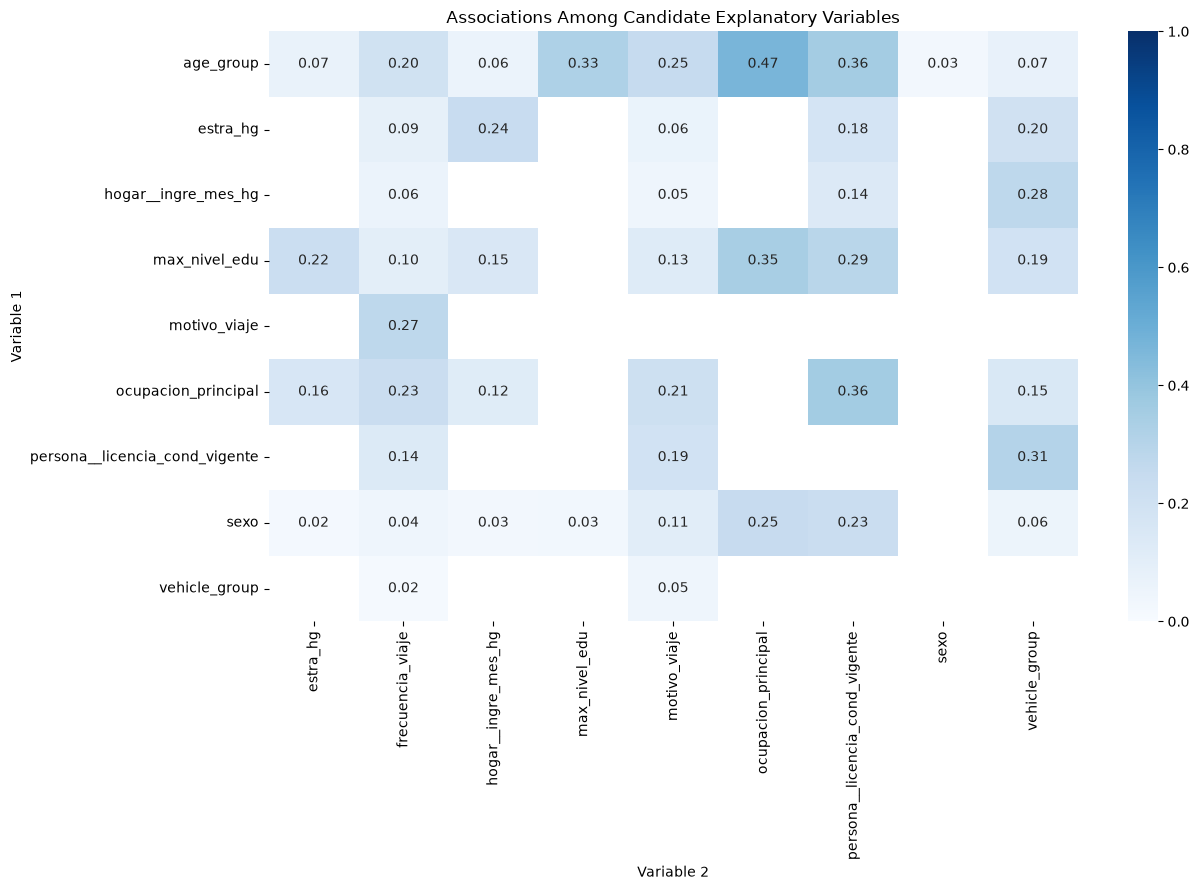

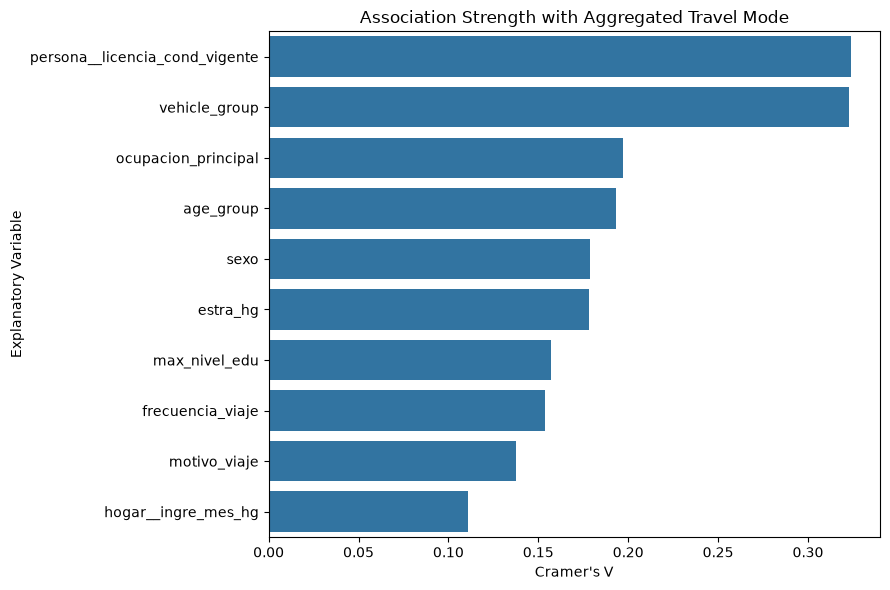

In [174]:
import matplotlib.pyplot as plt
import seaborn as sns

# Predictor-to-predictor associations
association_plot = association_matrix.pivot(
    index="Variable 1",
    columns="Variable 2",
    values="Cramer's V"
)

plt.figure(figsize=(13, 9))
sns.heatmap(
    association_plot,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1
)
plt.title("Associations Among Candidate Explanatory Variables")
plt.tight_layout()
plt.show()


# Associations with travel mode choice
plt.figure(figsize=(9, 6))
sns.barplot(
    data=target_associations,
    x="Cramer's V",
    y="Variable"
)
plt.title("Association Strength with Aggregated Travel Mode")
plt.xlabel("Cramer's V")
plt.ylabel("Explanatory Variable")
plt.tight_layout()
plt.show()

In [176]:

selected_pairs = [
    ("age_group", "ocupacion_principal"),
    ("max_nivel_edu", "ocupacion_principal"),
    ("persona__licencia_cond_vigente", "vehicle_group"),
    ("estra_hg", "hogar__ingre_mes_hg")
]

for var1, var2 in selected_pairs:

    print(f"\n{var1} vs {var2}")

    table = pd.crosstab(
        df_assoc[var1],
        df_assoc[var2],
        normalize="index"
    ) * 100

    display(table.round(1))



age_group vs ocupacion_principal


ocupacion_principal,Buscar trabajo,Colegio o escuela,Conductor/mensajero,Dedicado al hogar,Empleado de empresa particular,Empleado doméstico,Empleado público,Incapacitado permanente,Inst Técnico / Tecnológico,Inst educación no formal,...,Otra actividad,Patrón/empleador,Profesional independiente,Rentista,Trabajador independiente,Trabajador sin remuneración,Universidad - Posgrado,Universidad – Pregrado,Va a jardín,Vendedor informal
age_group,,,,,,,,,,,,,,,,,,,,,
5-17,0.1,94.1,0.0,0.4,0.3,0.0,0.0,0.1,0.6,0.2,...,0.9,0.0,0.0,0.0,0.3,0.0,0.0,1.1,0.4,0.0
18-24,3.9,5.3,0.5,4.8,32.0,0.4,1.2,0.1,5.1,0.5,...,1.9,0.0,1.1,0.0,12.0,0.1,1.1,26.4,0.0,1.1
25-34,3.1,0.3,1.0,8.9,47.3,1.0,3.7,0.2,0.6,0.1,...,1.1,0.2,4.9,0.0,19.9,0.1,0.9,2.7,0.0,1.6
35-44,2.1,0.1,1.0,9.5,41.1,1.8,4.7,0.3,0.2,0.0,...,1.2,0.4,6.9,0.1,26.0,0.1,0.2,0.2,0.0,1.5
45-54,2.1,0.1,1.3,14.6,29.7,1.6,4.2,0.5,0.1,0.0,...,1.1,0.7,8.2,0.2,29.6,0.2,0.1,0.1,0.0,1.7
55-64,1.8,0.1,0.9,23.9,15.0,1.4,2.8,0.6,0.1,0.0,...,1.5,0.5,6.2,0.4,27.9,0.2,0.0,0.0,0.0,1.8
65-74,0.7,0.0,0.5,30.9,2.7,0.4,0.6,0.8,0.0,0.0,...,1.5,0.2,2.7,0.5,17.3,0.2,0.0,0.0,0.0,1.4
75+,0.1,0.0,0.1,35.6,0.6,0.1,0.2,1.9,0.0,0.0,...,1.7,0.1,1.0,1.4,6.3,0.0,0.0,0.1,0.0,0.6



max_nivel_edu vs ocupacion_principal


ocupacion_principal,Buscar trabajo,Colegio o escuela,Conductor/mensajero,Dedicado al hogar,Empleado de empresa particular,Empleado doméstico,Empleado público,Incapacitado permanente,Inst Técnico / Tecnológico,Inst educación no formal,...,Otra actividad,Patrón/empleador,Profesional independiente,Rentista,Trabajador independiente,Trabajador sin remuneración,Universidad - Posgrado,Universidad – Pregrado,Va a jardín,Vendedor informal
max_nivel_edu,,,,,,,,,,,,,,,,,,,,,
Media completa (10° y 11°),3.8,1.5,1.6,16.5,34.9,1.4,1.0,0.3,0.9,0.2,...,1.4,0.2,0.7,0.1,25.7,0.2,0.0,0.9,0.0,1.7
Media incompleta (10° y 11°),1.3,53.9,0.7,9.0,11.1,0.7,0.0,0.3,0.1,0.3,...,1.2,0.0,0.4,0.1,12.8,0.0,0.0,0.2,0.0,2.3
Ninguno,0.6,7.1,0.8,29.1,8.1,1.3,0.0,5.6,0.4,0.0,...,3.2,0.5,1.3,0.9,17.5,0.2,0.0,0.9,0.4,2.3
Posgrado completo,0.7,0.1,0.0,2.1,34.4,0.1,16.6,0.0,0.1,0.1,...,1.0,2.2,20.5,0.3,8.4,0.0,0.6,0.2,0.0,0.0
Posgrado incompleto,0.6,0.0,0.0,1.8,24.9,0.0,10.4,0.0,0.0,0.6,...,0.0,0.0,13.3,0.0,5.9,0.0,28.7,8.9,0.0,0.0
Preescolar,0.2,88.5,0.0,1.3,0.3,0.0,0.0,0.3,0.0,0.0,...,1.3,0.0,0.2,0.0,0.6,0.2,0.0,0.0,4.8,0.0
Primaria completa,1.6,5.1,1.1,29.9,12.0,2.5,0.3,0.8,0.0,0.0,...,1.5,0.1,0.5,0.5,25.4,0.1,0.0,0.0,0.0,2.7
Primaria incompleta,0.7,57.8,0.2,14.9,3.3,0.8,0.2,0.9,0.0,0.0,...,1.3,0.0,0.4,0.2,9.6,0.1,0.0,0.0,0.0,1.4
Secundaria completa,2.7,4.5,1.3,16.4,29.3,1.3,1.1,0.2,0.3,0.1,...,1.4,0.0,0.7,0.1,28.3,0.2,0.0,0.9,0.0,1.8



persona__licencia_cond_vigente vs vehicle_group


vehicle_group,0,1,2+
persona__licencia_cond_vigente,,,
Moto,9.4,58.0,32.6
No aplica,44.6,37.3,18.1
No tiene,53.3,35.8,10.9
Todas las anteriores,13.0,37.5,49.5
Transporte público,31.0,44.9,24.1
Transporte público/moto,19.6,26.1,54.3
Vehículo parti./transp. público,20.2,49.0,30.8
Vehículo particular,12.7,51.4,35.8
Vehículo particular/moto,7.7,29.8,62.5



estra_hg vs hogar__ingre_mes_hg


hogar__ingre_mes_hg,0-400000,1160001-1500000,1500001-2000000,2000001-2500000,2500001-3500000,3500001-4900000,400001-800000,4900001-6800000,6800001-9000000,800001-1160000,>9000000,NS/NR
estra_hg,,,,,,,,,,,,
1,4.9,19.4,15.0,11.9,5.4,2.3,10.1,1.0,0.1,20.3,0.0,9.7
2,2.7,15.0,14.4,12.4,10.8,5.6,6.4,1.6,0.4,14.7,0.1,15.8
3,0.8,9.4,10.4,11.7,14.8,10.6,2.4,5.6,2.1,6.9,1.3,24.0
4,0.2,2.1,5.0,5.7,9.1,11.5,0.6,10.7,7.4,1.4,6.6,39.8
5,0.1,1.4,1.4,2.0,3.6,11.8,0.2,18.1,15.3,1.2,11.5,33.5
6,0.0,0.6,0.3,1.2,1.8,6.8,0.0,10.7,8.4,0.7,17.7,51.9
No aplica,1.5,15.3,13.4,14.3,12.0,7.1,3.1,2.6,0.9,11.8,0.6,17.4


<!-- 1. Cierre de la selección preliminar de variables
Variables candidatas prioritarias
Grupo	Variable	Justificación
Demográfica	edad	Diferencias en patrones de movilidad por ciclo de vida.
Socioeconómica	hogar__ingre_mes_hg	Gradiente claro entre ingreso y elección modal.
Socioeconómica	estra_hg	Diferencias modales importantes entre estratos.
Recursos del hogar	vehicle_records_in_household	Asociación marcada con auto, moto y transporte público.
Individual	persona__licencia_cond_vigente	Relación directa entre tipo de licencia y modos motorizados.
Actividad	motivo_viaje	La distribución modal cambia según el propósito del viaje.

Variables candidatas secundarias
- sexo
- max_nivel_edu
- ocupacion_principal
- hogar__perstotal_hg
- hogar__pers>18años_hg
- hogar__tipo_viv
- frecuencia_viaje — pendiente validar exactamente qué mide en el cuestionario.
Variables para análisis específico o baja prioridad
- madre_cab_familia: análisis de heterogeneidad para mujeres de 15 años o más; no como predictor general.
- hogar__pers>5años_hg: baja prioridad por su posible redundancia con el tamaño total del hogar.
- app_antes_vj: excluir de la especificación inicial; solo el 3% de las observaciones reporta uso.
Variables auxiliares y objetivos
- fexp_vj: factor para análisis descriptivo ponderado; no predictor.
- modo_principal_agrupado: variable objetivo principal inicial.
- modo_principal_desagrupado: alternativa para una especificación más detallada. No utilizar ambos objetivos simultáneamente.
Una precaución importante: ingreso, estrato y registros vehiculares están relacionados entre sí. No debemos asumir que los tres aportan información independiente. Precisamente eso será parte del análisis multivariado.


### 2.10.1
 Preliminary Variable Selection

| Priority | Variable group | Variables |
|---|---|---|
| High | Demographic and socioeconomic | `edad`, `hogar__ingre_mes_hg`, `estra_hg` |
| High | Household resources | `vehicle_records_in_household` |
| High | Individual and trip characteristics | `persona__licencia_cond_vigente`, `motivo_viaje` |
| Secondary | Demographic and socioeconomic | `sexo`, `max_nivel_edu`, `ocupacion_principal` |
| Secondary | Household characteristics | `hogar__perstotal_hg`, `hogar__pers>18años_hg`, `hogar__tipo_viv` |
| Conditional | Travel behavior | `frecuencia_viaje` (pending definition validation) |
| Subgroup analysis | Family characteristics | `madre_cab_familia` |
| Low priority | Household composition | `hogar__pers>5años_hg` |
| Excluded initially | Application use | `app_antes_vj` |
| Auxiliary | Survey expansion factor | `fexp_vj` | -->


Preliminary Variable Selection

| Priority | Variable group | Variables |
|---|---|---|
| High | Demographic and socioeconomic | `edad`, `hogar__ingre_mes_hg`, `estra_hg` |
| High | Household resources | `vehicle_records_in_household` |
| High | Individual and trip characteristics | `persona__licencia_cond_vigente`, `motivo_viaje` |
| Secondary | Demographic and socioeconomic | `sexo`, `max_nivel_edu`, `ocupacion_principal` |
| Secondary | Household characteristics | `hogar__perstotal_hg`, `hogar__pers>18años_hg`, `hogar__tipo_viv` |
| Conditional | Travel behavior | `frecuencia_viaje` (pending definition validation) |
| Subgroup analysis | Family characteristics | `madre_cab_familia` |
| Low priority | Household composition | `hogar__pers>5años_hg` |
| Excluded initially | Application use | `app_antes_vj` |
| Auxiliary | Survey expansion factor | `fexp_vj` |

### 3. analisis particulares seleccion parametros


#### 3.1 Licencia de conduccion

In [177]:

# Inspect driving license categories and their frequencies

license_counts = (
    df["persona__licencia_cond_vigente"]
    .value_counts(dropna=False)
    .rename_axis("license_category")
    .reset_index(name="trips")
)

license_counts["percentage"] = (
    license_counts["trips"] / len(df) * 100
).round(2)

display(license_counts)


,license_category,trips,percentage
0,No tiene,57316,57.22
1,Vehículo particular,18272,18.24
2,No aplica,12914,12.89
3,Moto,5230,5.22
4,Vehículo particular/moto,4141,4.13
5,Vehículo parti./transp. público,1008,1.01
6,Transporte público,639,0.64
7,Todas las anteriores,608,0.61
8,Transporte público/moto,46,0.05


In [229]:
# ============================================================
# 3.1. CREATE DRIVING LICENSE INDICATORS
# ============================================================

df_model = df.copy()

license_mapping = {
    "No tiene": (0, 0, 0),
    "No aplica": (0, 0, 0),
    "Vehículo particular": (1, 0, 0),
    "Moto": (0, 1, 0),
    "Vehículo particular/moto": (1, 1, 0),
    "Vehículo parti./transp. público": (1, 0, 1),
    "Transporte público": (0, 0, 1),
    "Todas las anteriores": (1, 1, 1),
    "Transporte público/moto": (0, 1, 1)
}

license_columns = [
    "has_car_license",
    "has_motorcycle_license",
    "has_public_transport_license"
]

license_values = df_model[
    "persona__licencia_cond_vigente"
].map(license_mapping)

df_model[license_columns] = pd.DataFrame(
    license_values.tolist(),
    index=df_model.index,
    columns=license_columns
).astype("int8")

# Validate license indicators
display(
    df_model[license_columns]
    .value_counts()
    .to_frame("observations")
)

print("Missing values:")
display(df_model[license_columns].isna().sum())

observations
has_car_license has_motorcycle_license has_public_transport_license              
0               0                      0                                    70230
1               0                      0                                    18272
0               1                      0                                     5230
1               1                      0                                     4141
                0                      1                                     1008
0               0                      1                                      639
1               1                      1                                      608
0               1                      1                                       46

Missing values:


has_car_license                 0
has_motorcycle_license          0
has_public_transport_license    0
dtype: int64

In [230]:

# Compare driving license indicators across travel modes

license_mode_profile = (
    df_model
    .groupby("modo_principal_agrupado")[license_columns]
    .mean()
    .mul(100)
    .round(2)
)

display(license_mode_profile)

    

,has_car_license,has_motorcycle_license,has_public_transport_license
modo_principal_agrupado,,,
A PIE <15 MIN,14.18,4.15,1.59
A PIE > 15 MIN,13.03,3.18,1.18
AUTO,76.01,11.29,4.94
BICICLETA,18.89,8.39,2.06
ESPECIAL OCUPADO,25.73,6.31,3.23
INFORMAL,9.23,5.31,2.88
MOTO,30.72,82.33,3.70
OTRO,46.69,12.05,28.31
TAXI OCUPADO,32.02,3.83,3.46


In [234]:
# ============================================================
# VERIFY AGE PATTERN IN NOT APPLICABLE LICENSE CATEGORY
# ============================================================

df_people = df_model.drop_duplicates(subset="key_pers").copy()

license_age_check = (
    df_people
    .groupby("persona__licencia_cond_vigente", dropna=False)
    .agg(
        persons=("key_pers", "nunique"),
        under_16=("edad", lambda x: (x < 16).sum()),
        age_16_plus=("edad", lambda x: (x >= 16).sum()),
        min_age=("edad", "min"),
        max_age=("edad", "max")
    )
)

license_age_check["under_16_pct"] = (
    license_age_check["under_16"]
    / license_age_check["persons"] * 100
)

display(license_age_check.round(2))

,persons,under_16,age_16_plus,min_age,max_age,under_16_pct
persona__licencia_cond_vigente,,,,,,
Moto,2552,0,2552,17,87,0.00
No aplica,6491,6485,6,5,37,99.91
No tiene,27798,0,27798,16,99,0.00
Todas las anteriores,275,0,275,19,73,0.00
Transporte público,318,0,318,19,77,0.00
Transporte público/moto,24,0,24,20,62,0.00
Vehículo parti./transp. público,471,0,471,19,84,0.00
Vehículo particular,8682,0,8682,16,92,0.00
Vehículo particular/moto,1928,0,1928,16,77,0.00


In [235]:
# ============================================================
# FINALIZE LICENSE INDICATORS
# ============================================================

df_analytical = df_model.copy()

license_cols = [
    "has_car_license",
    "has_motorcycle_license",
    "has_public_transport_license"
]

# Encode "Not applicable" as zero across license indicators
df_analytical[license_cols] = (
    df_analytical[license_cols]
    .fillna(0)
    .astype("int8")
)

# Validate final coding
print("Total observations:", len(df_analytical))
print("\nMissing values:")
display(df_analytical[license_cols].isna().sum())

print("\nLicense combinations:")
display(
    df_analytical[license_cols]
    .value_counts()
    .to_frame("observations")
)

Total observations: 100174

Missing values:


has_car_license                 0
has_motorcycle_license          0
has_public_transport_license    0
dtype: int64


License combinations:


observations
has_car_license has_motorcycle_license has_public_transport_license              
0               0                      0                                    70230
1               0                      0                                    18272
0               1                      0                                     5230
1               1                      0                                     4141
                0                      1                                     1008
0               0                      1                                      639
1               1                      1                                      608
0               1                      1                                       46

License Variables: Recoding and Methodological Decision

**Original variable:** `persona__licencia_cond_vigente`

The original survey variable identifies the respondent's current driving-license status through multiple categories, including no license, not applicable, and different combinations of license types.

1. Exploratory assessment

The original category `No aplica` contained 6,491 unique individuals. An age-based assessment showed that:

- 6,485 individuals (99.91%) were younger than 16 years.
- Only 6 individuals (0.09%) were aged 16 or older.
- The mean age in this category was 10.2 years, compared with 42.7 years for individuals classified as `No tiene`.

Furthermore, no individuals younger than 16 were observed in the `No tiene` category or in the reported license-holding categories.

These results suggest that `No aplica` is strongly associated with age and represents a population for which the driving-license question generally does not apply.

2. Recoding strategy

Three binary indicators were retained to represent the reported license types:

- `has_car_license`
- `has_motorcycle_license`
- `has_public_transport_license`

The original categories `No tiene` and `No aplica` were both coded as zero across the three indicators. Individuals reporting multiple license types retained the corresponding combination of ones.

No additional `license_not_applicable` indicator was created.

 3. Methodological justification

This decision preserves the distinction between license ownership combinations while allowing age to capture relevant differences between individuals with no reported license.

The model can therefore distinguish, through the combination of age and license indicators, between younger individuals for whom a license is generally not applicable and older individuals who report having no license.

This approach avoids introducing an additional indicator that would largely duplicate age-related information, while preserving all observations.

4. Limitations

The observed association between `No aplica` and age is empirical evidence, not confirmation of the survey's official coding rule. The six individuals aged 16 or older in this category were retained and coded as zero across the three indicators.

The resulting variables represent reported license status, not actual vehicle availability or the individual's effective ability to access a vehicle.

**Final decision:** `No aplica` and `No tiene` are both represented as `(0, 0, 0)` in the three license indicators. Age remains a separate explanatory variable in the modeling framework.

#### 3.2 Motivos de viaje

In [236]:

# Inspect trip purpose categories and their frequencies

purpose_counts = (
    df["motivo_viaje"]
    .value_counts(dropna=False)
    .rename_axis("trip_purpose")
    .reset_index(name="trips")
)

purpose_counts["percentage"] = (
    purpose_counts["trips"] / len(df) * 100
).round(2)

display(purpose_counts)


,trip_purpose,trips,percentage
0,A regresar al hogar,47672,47.59
1,A trabajar,20821,20.78
2,A Estudiar,9417,9.40
3,A realizar algún trámite personal,4904,4.90
4,A realizar compras,4662,4.65
5,A acompañar a alguien sin remuneración,3899,3.89
6,A asuntos médicos personales,3669,3.66
7,A visitar a alguien,1450,1.45
8,A realizar actividades recreativas y culturales,1235,1.23
9,A realizar actividades físicas y/o deportivas,997,1.00


In [237]:

# Analyze travel mode distribution by trip purpose

purpose_mode_profile = pd.crosstab(
    df["motivo_viaje"],
    df["modo_principal_agrupado"],
    normalize="index"
).mul(100).round(2)

display(purpose_mode_profile)


modo_principal_agrupado,A PIE <15 MIN,A PIE > 15 MIN,AUTO,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
motivo_viaje,,,,,,,,,,,
A Estudiar,18.86,35.78,3.97,3.87,1.47,0.87,2.89,0.05,0.87,10.44,20.94
A acompañar a alguien con remuneración,23.29,37.67,15.07,4.11,0.00,2.74,2.05,0.00,3.42,0.00,11.64
A acompañar a alguien sin remuneración,23.75,35.01,15.36,4.00,1.13,1.00,4.15,0.10,3.85,0.05,11.59
A asistir actividad de tipo religioso y/o culto,21.09,33.33,14.97,1.70,0.68,1.36,1.02,1.02,9.86,0.00,14.97
A asuntos médicos personales,2.43,12.54,14.80,1.69,2.81,1.44,1.50,0.19,13.82,0.00,48.79
A buscar trabajo,3.38,20.68,1.69,10.13,0.42,0.42,2.11,0.00,0.84,0.00,60.34
A llevar y/o dejar algo,20.81,31.65,14.45,8.09,0.58,1.16,7.08,0.58,0.87,0.00,14.74
A realizar actividades físicas y/o deportivas,27.88,48.35,7.12,9.23,0.30,0.20,1.60,0.50,1.00,0.20,3.61
A realizar actividades recreativas y culturales,17.81,30.85,26.07,3.97,3.00,0.81,2.02,0.24,4.86,0.32,10.04


In [238]:
# Normalize travel purpose labels and apply grouping

purpose_mapping = {
    "A Estudiar": "EDUCATION",
    "A trabajar": "WORK",
    "Conduzco vehículo como forma de trabajo": "WORK",
    "A buscar trabajo": "WORK",
    "A regresar al hogar": "HOME_RETURN",
    "A acompañar a alguien con remuneración": "ESCORT",
    "A acompañar a alguien sin remuneración": "ESCORT",
    "A asuntos médicos personales": "HEALTH",
    "A realizar algún trámite personal": "PERSONAL_ERRANDS",
    "A realizar compras": "PERSONAL_ERRANDS",
    "A llevar y/o dejar algo": "PERSONAL_ERRANDS",
    "A realizar actividades recreativas y culturales": "LEISURE",
    "A realizar actividades físicas y/o deportivas": "LEISURE",
    "A visitar a alguien": "SOCIAL_RELIGIOUS",
    "A asistir actividad de tipo religioso y/o culto": "SOCIAL_RELIGIOUS"
}

purpose_clean = df_model["motivo_viaje"].str.strip()

df_model["purpose_group"] = purpose_clean.map(purpose_mapping)

display(
    df_model["purpose_group"]
    .value_counts(dropna=False)
    .to_frame("trips")
    .assign(
        percentage=lambda x: (
            x["trips"] / len(df_model) * 100
        ).round(2)
    )
)

,trips,percentage
purpose_group,,
HOME_RETURN,47672,47.59
WORK,21115,21.08
PERSONAL_ERRANDS,10258,10.24
EDUCATION,9417,9.40
ESCORT,4045,4.04
HEALTH,3669,3.66
LEISURE,2232,2.23
SOCIAL_RELIGIOUS,1744,1.74
NaN,22,0.02


#### 3.3 Hora de inicio

In [239]:
# Inspect trip start time distribution

print("Data type:", df_model["hora_ini"].dtype)
print("Missing values:", df_model["hora_ini"].isna().sum())
print("Unique values:", df_model["hora_ini"].nunique())

display(
    df_model["hora_ini"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("trips")
)

Data type: float64
Missing values: 9
Unique values: 1238


,trips
hora_ini,
0.02,2
0.03,1
0.07,1
0.08,5
0.12,1
...,...
23.87,1
23.92,3
23.95,1


In [240]:
# Convert trip start time to numeric
hour = pd.to_numeric(df_model["hora_ini"], errors="coerce")

# 2 periods: peak vs. off-peak
df_model["time_period_2"] = np.select(
    [
        hour.between(6.5, 9, inclusive="left"),
        hour.between(16, 18.5, inclusive="left")
    ],
    ["PEAK", "PEAK"],
    default="OFF_PEAK"
)

df_model.loc[hour.isna(), "time_period_2"] = np.nan

# 4 periods
df_model["time_period_4"] = pd.cut(
    hour,
    bins=[0, 6.5, 9, 16, 24],
    labels=["OVERNIGHT", "AM_PEAK", "DAYTIME", "EVENING"],
    right=False
)

# 6 periods
df_model["time_period_6"] = pd.cut(
    hour,
    bins=[0, 6.5, 9, 12, 16, 18.5, 24],
    labels=[
        "OVERNIGHT",
        "AM_PEAK",
        "AM_OFF_PEAK",
        "PM_OFF_PEAK",
        "PM_PEAK",
        "EVENING"
    ],
    right=False
)

# Compare period sizes
for col in ["time_period_2", "time_period_4", "time_period_6"]:
    print(f"\n{col}")
    display(
        df_model[col]
        .value_counts(dropna=False)
        .to_frame("trips")
        .assign(
            percentage=lambda x: (
                x["trips"] / len(df_model) * 100
            ).round(2)
        )
    )


time_period_2


,trips,percentage
time_period_2,,
OFF_PEAK,65432,65.32
PEAK,34733,34.67
NaN,9,0.01



time_period_4


,trips,percentage
time_period_4,,
DAYTIME,41966,41.89
EVENING,24051,24.01
AM_PEAK,18142,18.11
OVERNIGHT,16006,15.98
NaN,9,0.01



time_period_6


,trips,percentage
time_period_6,,
PM_OFF_PEAK,24390,24.35
AM_PEAK,18142,18.11
AM_OFF_PEAK,17576,17.55
PM_PEAK,16591,16.56
OVERNIGHT,16006,15.98
EVENING,7460,7.45
NaN,9,0.01


In [241]:
# Compare modal distribution across the six time periods

mode_time_profile = pd.crosstab(
    df_model["time_period_6"],
    df_model["modo_principal_agrupado"],
    normalize="index"
).mul(100).round(2)

display(mode_time_profile)

modo_principal_agrupado,A PIE <15 MIN,A PIE > 15 MIN,AUTO,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
time_period_6,,,,,,,,,,,
OVERNIGHT,8.49,19.28,8.80,7.28,3.19,0.91,8.00,0.33,1.87,4.23,37.61
AM_PEAK,13.54,22.78,13.70,6.96,1.35,0.77,6.77,0.31,3.37,1.34,29.13
AM_OFF_PEAK,15.60,32.22,13.11,4.26,1.25,0.90,3.64,0.33,5.01,0.75,22.94
PM_OFF_PEAK,14.92,30.10,12.19,5.18,2.24,0.89,4.08,0.31,3.21,3.41,23.47
PM_PEAK,8.75,20.37,13.25,7.06,1.74,0.78,8.28,0.39,2.47,0.91,36.03
EVENING,9.97,17.83,16.30,6.60,2.29,1.02,9.79,0.32,3.81,0.34,31.74


In [242]:
# Test association between time period and travel mode

from scipy.stats import chi2_contingency
import numpy as np

contingency_table = pd.crosstab(
    df_model["time_period_6"],
    df_model["modo_principal_agrupado"]
)

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

n = contingency_table.to_numpy().sum()
min_dim = min(contingency_table.shape) - 1

cramers_v = np.sqrt(chi2 / (n * min_dim))

print(f"Chi-square statistic: {chi2:.2f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.6e}")
print(f"Cramer's V: {cramers_v:.4f}")

Chi-square statistic: 5791.56
Degrees of freedom: 50
P-value: 0.000000e+00
Cramer's V: 0.1075


Final temporal variable: six mobility-based time periods
Periods distinguish overnight, morning peak, morning off-peak,
afternoon off-peak, afternoon peak, and evening travel.
Original variable hora_ini is preserved.

#### 3.4 Escala Espacial

In [243]:
# Inspect spatial variables

spatial_variables = [
    "localidad_ori",
    "territory_name_ori",
    "zat_centroid_distance_m"
]

for col in spatial_variables:
    print(f"\n{'='*50}")
    print(f"Variable: {col}")
    print("Data type:", df_model[col].dtype)
    print("Missing:", df_model[col].isna().sum())
    print("Unique values:", df_model[col].nunique())

    if col != "zat_centroid_distance_m":
        display(
            df_model[col]
            .value_counts(dropna=False)
            .head(30)
            .to_frame("trips")
        )
    else:
        display(
            df_model[col].describe(
                percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
            ).to_frame("value")
        )


Variable: localidad_ori
Data type: object
Missing: 0
Unique values: 21


,trips
localidad_ori,
No aplica,21142
Kennedy,8745
Ciudad Bolivar,7684
Chapinero,6301
Suba,6269
Usaquen,5975
Teusaquillo,4908
Engativa,4647
Fontibon,4286



Variable: territory_name_ori
Data type: object
Missing: 0
Unique values: 55


,trips
territory_name_ori,
Kennedy,8745
Ciudad Bolivar,7684
Chapinero,6301
Suba,6269
Usaquen,5975
Soacha,4915
Teusaquillo,4908
Engativa,4647
Fontibon,4286



Variable: zat_centroid_distance_m
Data type: float64
Missing: 0
Unique values: 25264


,value
count,100174.000000
mean,5928.484041
std,7569.644172
min,0.000000
1%,0.000000
5%,0.000000
25%,913.661549
50%,3245.071924
75%,8717.937242
95%,19136.245661


In [244]:
# Spatial relevance diagnostics

# 1. Modal distribution by territory of origin
territory_mode = pd.crosstab(
    df_model["territory_name_ori"],
    df_model["modo_principal_agrupado"],
    normalize="index"
).mul(100).round(2)

territory_counts = (
    df_model["territory_name_ori"]
    .value_counts()
    .rename("trips")
)

# Show territories with at least 500 trips
valid_territories = territory_counts[
    territory_counts >= 500
].index

display(
    territory_mode.loc[territory_mode.index.isin(valid_territories)]
)

modo_principal_agrupado,A PIE <15 MIN,A PIE > 15 MIN,AUTO,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
territory_name_ori,,,,,,,,,,,
Antonio Nariño,12.61,21.44,7.86,4.98,0.96,0.85,6.05,0.28,3.96,1.36,39.65
Barrios Unidos,13.18,19.52,15.04,7.32,1.74,0.15,5.40,0.24,6.04,1.83,29.53
Bojacá,18.30,40.19,7.69,10.48,2.65,0.40,6.10,0.27,0.40,1.86,11.67
Bosa,15.99,30.83,6.08,9.11,1.50,1.65,5.29,0.32,2.20,0.88,26.13
Cajicá,5.38,26.09,21.40,15.10,3.20,0.00,5.84,0.11,0.23,2.17,20.48
Candelaria,18.28,27.14,9.90,1.98,0.66,0.09,4.34,0.09,4.81,0.38,32.33
Chapinero,5.98,14.62,24.36,2.79,1.65,0.22,6.59,0.21,5.65,1.48,36.45
Choachí,32.80,37.08,10.16,1.60,1.78,0.71,5.53,0.18,0.53,1.78,7.84
Chía,5.56,17.56,19.24,22.17,2.85,0.37,5.27,0.15,1.68,4.46,20.70


In [245]:
# Descriptive statistics of centroid distance by travel mode

distance_by_mode = (
    df_model
    .groupby("modo_principal_agrupado")["zat_centroid_distance_m"]
    .describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
    )
    .round(2)
)

display(distance_by_mode)

,count,mean,std,min,10%,25%,50%,75%,90%,95%,max
modo_principal_agrupado,,,,,,,,,,,
A PIE <15 MIN,12392.0,1740.39,4443.71,0.0,0.00,0.00,463.72,1226.72,4249.15,9563.98,71691.62
A PIE > 15 MIN,24932.0,2364.93,4897.28,0.0,0.00,0.00,970.41,2063.67,5620.68,11333.10,90216.95
AUTO,12586.0,7600.66,8753.55,0.0,1005.78,2330.60,5169.62,9788.30,16052.34,22665.16,94613.54
BICICLETA,6104.0,4479.41,5346.14,0.0,0.00,1217.14,2787.11,5919.38,10663.25,13865.53,77234.11
ESPECIAL OCUPADO,1982.0,7187.87,8215.13,0.0,440.06,2220.16,4802.38,9540.63,15587.00,20646.36,86186.67
INFORMAL,867.0,5032.14,5384.75,0.0,797.95,1765.36,3213.01,6307.53,12531.32,14962.18,51671.52
MOTO,6247.0,8907.07,8451.31,0.0,1082.11,3127.14,7012.83,12426.15,17985.62,22184.23,92320.81
OTRO,332.0,10303.07,15373.94,0.0,405.23,1689.96,4949.44,11885.51,23587.21,36995.19,94964.09
TAXI OCUPADO,3267.0,5238.34,5436.33,0.0,1005.78,2093.94,3882.34,6973.36,11088.64,13633.01,102078.88


In [246]:
# Zero-distance diagnostics by travel mode

zero_distance_by_mode = (
    df_model
    .assign(
        zero_distance=lambda x: x["zat_centroid_distance_m"].eq(0)
    )
    .groupby("modo_principal_agrupado")
    .agg(
        total_trips=("zat_centroid_distance_m", "count"),
        zero_distance_trips=("zero_distance", "sum"),
        mean_distance=("zat_centroid_distance_m", "mean")
    )
)

zero_distance_by_mode["zero_distance_pct"] = (
    zero_distance_by_mode["zero_distance_trips"]
    / zero_distance_by_mode["total_trips"] * 100
).round(2)

display(zero_distance_by_mode.round(2))

,total_trips,zero_distance_trips,mean_distance,zero_distance_pct
modo_principal_agrupado,,,,
A PIE <15 MIN,12392,5636,1740.39,45.48
A PIE > 15 MIN,24932,6739,2364.93,27.03
AUTO,12586,661,7600.66,5.25
BICICLETA,6104,634,4479.41,10.39
ESPECIAL OCUPADO,1982,194,7187.87,9.79
INFORMAL,867,49,5032.14,5.65
MOTO,6247,284,8907.07,4.55
OTRO,332,33,10303.07,9.94
TAXI OCUPADO,3267,94,5238.34,2.88


In [247]:
# Distance distribution by travel mode, excluding zero distances

positive_distance_by_mode = (
    df_model.loc[
        df_model["zat_centroid_distance_m"] > 0
    ]
    .groupby("modo_principal_agrupado")["zat_centroid_distance_m"]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90]
    )
    .round(2)
)

display(positive_distance_by_mode)

,count,mean,std,min,25%,50%,75%,90%,max
modo_principal_agrupado,,,,,,,,,
A PIE <15 MIN,6756.0,3192.26,5620.19,194.51,676.78,1107.21,2951.61,9034.48,71691.62
A PIE > 15 MIN,18193.0,3240.94,5479.82,184.13,848.59,1391.26,2919.27,8034.72,90216.95
AUTO,11925.0,8021.96,8802.97,349.08,2706.86,5524.12,10139.11,16369.83,94613.54
BICICLETA,5470.0,4998.59,5412.84,257.00,1647.15,3277.63,6442.37,11182.29,77234.11
ESPECIAL OCUPADO,1788.0,7967.76,8282.37,330.91,3106.78,5481.34,10048.08,16474.34,86186.67
INFORMAL,818.0,5333.57,5396.75,420.44,2013.09,3394.97,6534.82,12890.06,51671.52
MOTO,5963.0,9331.29,8418.30,279.56,3568.48,7472.28,12755.38,18355.86,92320.81
OTRO,299.0,11440.19,15794.91,405.23,2143.43,6231.23,13965.21,26836.97,94964.09
TAXI OCUPADO,3173.0,5393.52,5439.88,294.06,2215.32,4024.27,7011.43,11174.80,102078.88


In [248]:
# Compare original and log-transformed distance distributions

distance = pd.to_numeric(
    df_model["zat_centroid_distance_m"],
    errors="coerce"
)

distance_comparison = pd.DataFrame({
    "Original_distance_m": distance,
    "Log_distance": np.log1p(distance)
}).describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).round(3)

display(distance_comparison)

,Original_distance_m,Log_distance
count,100174.000,100174.000
mean,5928.484,7.060
std,7569.644,3.136
min,0.000,0.000
10%,0.000,0.000
25%,913.662,6.819
50%,3245.072,8.085
75%,8717.937,9.073
90%,14682.788,9.594
95%,19136.246,9.859


In [249]:
# Create alternative distance specifications

df_model["log_distance"] = np.log1p(
    df_model["zat_centroid_distance_m"]
)

df_model["zero_distance"] = (
    df_model["zat_centroid_distance_m"] == 0
).astype("int8")

print(
    df_model[
        ["zat_centroid_distance_m", "log_distance", "zero_distance"]
    ].describe().round(3)
)

       zat_centroid_distance_m  log_distance  zero_distance
count               100174.000    100174.000     100174.000
mean                  5928.484         7.060          0.150
std                   7569.644         3.136          0.357
min                      0.000         0.000          0.000
25%                    913.662         6.819          0.000
50%                   3245.072         8.085          0.000
75%                   8717.937         9.073          0.000
max                 102078.878        11.534          1.000


#### 3.5 vehicle_records_in_household

In [250]:
# Inspect household vehicle records

vehicle_col = "vehicle_records_in_household"

print("Data type:", df_model[vehicle_col].dtype)
print("Missing values:", df_model[vehicle_col].isna().sum())

print("\nValue counts:")
display(
    df_model[vehicle_col]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("observations")
)

print("\nDescriptive statistics:")
display(
    df_model[vehicle_col]
    .describe()
    .to_frame("statistics")
)

Data type: int64
Missing values: 0

Value counts:


,observations
vehicle_records_in_household,
0,39911
1,40053
2,14981
3,3869
4,930
5,286
6,122
7,18
10,4



Descriptive statistics:


,statistics
count,100174.000000
mean,0.875177
std,0.925349
min,0.000000
25%,0.000000
50%,1.000000
75%,1.000000
max,10.000000


In [251]:
# Group household vehicle records into three categories

df_model["vehicle_availability"] = pd.cut(
    df_model["vehicle_records_in_household"],
    bins=[-1, 0, 1, float("inf")],
    labels=["0", "1", "2+"]
)

display(
    df_model["vehicle_availability"]
    .value_counts()
    .sort_index()
    .to_frame("observations")
)

,observations
vehicle_availability,
0,39911
1,40053
2+,20210


#### 3.6 	hogar__ingre_mes_hg

In [252]:
# Inspect household monthly income categories

income_col = "hogar__ingre_mes_hg"

print("Data type:", df_model[income_col].dtype)
print("Missing values:", df_model[income_col].isna().sum())

income_distribution = (
    df_model[income_col]
    .value_counts(dropna=False)
    .to_frame("observations")
)

income_distribution["percentage"] = (
    income_distribution["observations"]
    / len(df_model) * 100
).round(2)

display(income_distribution)

Data type: object
Missing values: 0


,observations,percentage
hogar__ingre_mes_hg,,
NS/NR,20892,20.86
1160001-1500000,12435,12.41
1500001-2000000,11658,11.64
2000001-2500000,11354,11.33
800001-1160000,11036,11.02
2500001-3500000,10545,10.53
3500001-4900000,7357,7.34
400001-800000,4359,4.35
4900001-6800000,4333,4.33


In [253]:
# Check unique income categories

print("Number of categories:", df_model[income_col].nunique())

display(
    df_model[income_col]
    .dropna()
    .unique()
)

Number of categories: 12


array(['NS/NR', '2000001-2500000', '800001-1160000', '1160001-1500000',
       '2500001-3500000', '1500001-2000000', '400001-800000', '0-400000',
       '3500001-4900000', '4900001-6800000', '6800001-9000000',
       '>9000000'], dtype=object)

In [254]:
# Group household monthly income into broader categories

income_mapping = {
    "NS/NR": "NS_NR",
    "0-400000": "LOW_INCOME",
    "400001-800000": "LOW_INCOME",
    "800001-1160000": "LOW_INCOME",
    "1160001-1500000": "MEDIUM_INCOME",
    "1500001-2000000": "MEDIUM_INCOME",
    "2000001-2500000": "MEDIUM_INCOME",
    "2500001-3500000": "MEDIUM_INCOME",
    "3500001-4900000": "HIGH_INCOME",
    "4900001-6800000": "HIGH_INCOME",
    "6800001-9000000": "HIGH_INCOME",
    ">9000000": "HIGH_INCOME"
}

df_model["income_group"] = (
    df_model["hogar__ingre_mes_hg"]
    .str.strip()
    .map(income_mapping)
)

display(
    df_model["income_group"]
    .value_counts(dropna=False)
    .to_frame("observations")
)

,observations
income_group,
MEDIUM_INCOME,45992
NS_NR,20892
LOW_INCOME,17332
HIGH_INCOME,15958


#### 3.7 	Frecuecnia vaije

In [255]:
# Inspect trip frequency variable

frequency_col = "frecuencia_viaje"

print("Data type:", df_model[frequency_col].dtype)
print("Missing values:", df_model[frequency_col].isna().sum())

frequency_distribution = (
    df_model[frequency_col]
    .value_counts(dropna=False)
    .to_frame("observations")
)

frequency_distribution["percentage"] = (
    frequency_distribution["observations"] / len(df_model) * 100
).round(2)

display(frequency_distribution)

print("\nUnique values:")
display(df_model[frequency_col].dropna().unique())

Data type: object
Missing values: 0


,observations,percentage
frecuencia_viaje,,
Prácticamente todos los días,54941,54.85
Varias veces a la semana,23665,23.62
En algunas ocasiones al mes,17662,17.63
Esporádicamente en el año,3586,3.58
Nunca lo realizo,320,0.32



Unique values:


array(['Prácticamente todos los días', 'En algunas ocasiones al mes',
       'Varias veces a la semana', 'Esporádicamente en el año',
       'Nunca lo realizo'], dtype=object)

In [256]:
# Trip frequency distribution by observed travel mode

frequency_mode = pd.crosstab(
    df_model[frequency_col],
    df_model["modo_principal_agrupado"],
    normalize="index"
).mul(100).round(2)

display(frequency_mode)

modo_principal_agrupado,A PIE <15 MIN,A PIE > 15 MIN,AUTO,BICICLETA,ESPECIAL OCUPADO,INFORMAL,MOTO,OTRO,TAXI OCUPADO,TRANSPORTE ESCOLAR,TRANSPORTE PÚBLICO
frecuencia_viaje,,,,,,,,,,,
En algunas ocasiones al mes,6.27,21.37,21.02,3.17,1.86,1.02,3.05,0.29,8.62,0.05,33.26
Esporádicamente en el año,3.71,13.75,27.33,2.62,2.48,1.00,4.18,0.45,10.21,0.00,34.27
Nunca lo realizo,2.81,13.12,29.06,3.12,3.44,0.94,4.69,0.00,10.62,0.00,32.19
Prácticamente todos los días,14.63,25.54,7.83,7.50,2.12,0.87,7.85,0.28,1.21,3.42,28.75
Varias veces a la semana,13.12,27.86,14.78,5.57,1.64,0.71,5.20,0.47,2.86,0.72,27.07


In [257]:
frequency_mapping = {
    "Prácticamente todos los días": "DAILY",
    "Varias veces a la semana": "WEEKLY",
    "En algunas ocasiones al mes": "RARELY",
    "Esporádicamente en el año": "RARELY",
    "Nunca lo realizo": "RARELY"
}

df_model["travel_frequency_3"] = (
    df_model["frecuencia_viaje"].map(frequency_mapping)
)

print("Travel frequency distribution:")
display(
    df_model["travel_frequency_3"]
    .value_counts(dropna=False)
    .to_frame("observations")
)

print("\nCross-check with original variable:")
display(pd.crosstab(
    df_model["frecuencia_viaje"],
    df_model["travel_frequency_3"],
    margins=True
))

Travel frequency distribution:


,observations
travel_frequency_3,
DAILY,54941
WEEKLY,23665
RARELY,21568



Cross-check with original variable:


travel_frequency_3,DAILY,RARELY,WEEKLY,All
frecuencia_viaje,,,,
En algunas ocasiones al mes,0,17662,0,17662
Esporádicamente en el año,0,3586,0,3586
Nunca lo realizo,0,320,0,320
Prácticamente todos los días,54941,0,0,54941
Varias veces a la semana,0,0,23665,23665
All,54941,21568,23665,100174


#### 3.8 Variables alternativas

In [258]:
# Review categories and frequencies before grouping
variables_to_review = [
    "max_nivel_edu",
    "ocupacion_principal",
    "hogar__perstotal_hg"
]

for col in variables_to_review:
    print(f"\n{'='*55}")
    print(f"{col} | Unique values: {df_model[col].nunique()}")
    print(f"{'='*55}")
    display(
        df_model[col]
        .value_counts(dropna=False)
        .rename("observations")
        .to_frame()
    )


max_nivel_edu | Unique values: 14


,observations
max_nivel_edu,
Media completa (10° y 11°),19357
Universitario completo,15058
Secundaria incompleta,10101
Primaria incompleta,9826
Técnico/Tecnológico completa,9494
Secundaria completa,8989
Primaria completa,8619
Universitario incompleto,5712
Posgrado completo,4496



ocupacion_principal | Unique values: 24


,observations
ocupacion_principal,
Empleado de empresa particular,25362
Trabajador independiente,18486
Colegio o escuela,15125
Dedicado al hogar,12649
Jubilado/pensionado,6229
Profesional independiente,4275
Universidad – Pregrado,4136
Empleado público,2549
Buscar trabajo,1989



hogar__perstotal_hg | Unique values: 11


,observations
hogar__perstotal_hg,
4,26209
3,25678
2,18273
5,13774
1,6520
6,5399
7,2514
8,950
9,494


In [259]:

# ============================================================
# SECONDARY VARIABLE GROUPING
# ============================================================

# 1. EDUCATION: 5 categories
education_mapping = {
    "Ninguno": "NO_FORMAL_OR_NONE",
    "Preescolar": "NO_FORMAL_OR_NONE",

    "Primaria incompleta": "PRIMARY",
    "Primaria completa": "PRIMARY",

    "Secundaria incompleta": "SECONDARY",
    "Secundaria completa": "SECONDARY",
    "Media incompleta (10° y 11°)": "SECONDARY",
    "Media completa (10° y 11°)": "SECONDARY",

    "Técnico/Tecnológico incompleta": "TECHNICAL_TECHNOLOGICAL",
    "Técnico/Tecnológico completa": "TECHNICAL_TECHNOLOGICAL",

    "Universitario incompleto": "UNIVERSITY_OR_HIGHER",
    "Universitario completo": "UNIVERSITY_OR_HIGHER",
    "Posgrado incompleto": "UNIVERSITY_OR_HIGHER",
    "Posgrado completo": "UNIVERSITY_OR_HIGHER"
}

df_model["education_group"] = (
    df_model["max_nivel_edu"]
    .astype("string")
    .str.strip()
    .map(education_mapping)
)


# 2. OCCUPATION: 5 categories
occupation_mapping = {
    # Employees
    "Empleado de empresa particular": "EMPLOYEE",
    "Empleado público": "EMPLOYEE",
    "Empleado doméstico": "EMPLOYEE",
    "Obrero": "EMPLOYEE",

    # Independent and self-employed workers
    "Trabajador independiente": "INDEPENDENT_WORKER",
    "Profesional independiente": "INDEPENDENT_WORKER",
    "Vendedor informal": "INDEPENDENT_WORKER",
    "Conductor/mensajero": "INDEPENDENT_WORKER",
    "Jornalero/agricultor": "INDEPENDENT_WORKER",
    "Patrón/empleador": "INDEPENDENT_WORKER",
    "Trabajador sin remuneración": "INDEPENDENT_WORKER",

    # Students
    "Colegio o escuela": "STUDENT",
    "Universidad – Pregrado": "STUDENT",
    "Universidad - Posgrado": "STUDENT",
    "Inst Técnico / Tecnológico": "STUDENT",
    "Inst educación no formal": "STUDENT",
    "Va a jardín": "STUDENT",

    # Household and retired
    "Dedicado al hogar": "HOME_AND_RETIRED",
    "Jubilado/pensionado": "HOME_AND_RETIRED",
    "Rentista": "HOME_AND_RETIRED",

    # Not employed or other
    "Buscar trabajo": "NOT_EMPLOYED_OR_OTHER",
    "No ocupado": "NOT_EMPLOYED_OR_OTHER",
    "Incapacitado permanente": "NOT_EMPLOYED_OR_OTHER",
    "Otra actividad": "NOT_EMPLOYED_OR_OTHER"
}

df_model["occupation_group"] = (
    df_model["ocupacion_principal"]
    .astype("string")
    .str.strip()
    .map(occupation_mapping)
)


# 3. HOUSEHOLD SIZE: 4 categories
household_size = pd.to_numeric(
    df_model["hogar__perstotal_hg"],
    errors="coerce"
)

df_model["household_size_group"] = pd.cut(
    household_size,
    bins=[0, 1, 3, 5, float("inf")],
    labels=[
        "1_PERSON",
        "2_3_PERSONS",
        "4_5_PERSONS",
        "6_OR_MORE"
    ],
    right=True
)


# 4. VALIDATION
grouped_variables = [
    "education_group",
    "occupation_group",
    "household_size_group"
]

for col in grouped_variables:
    print(f"\n{'='*50}")
    print(f"{col}")
    print(f"{'='*50}")
    display(
        df_model[col]
        .value_counts(dropna=False)
        .to_frame("observations")
    )



education_group


,observations
education_group,
SECONDARY,41739
UNIVERSITY_OR_HIGHER,25604
PRIMARY,18445
TECHNICAL_TECHNOLOGICAL,12062
NO_FORMAL_OR_NONE,2324



occupation_group


,observations
occupation_group,
EMPLOYEE,29836
INDEPENDENT_WORKER,25474
STUDENT,20703
HOME_AND_RETIRED,19057
NOT_EMPLOYED_OR_OTHER,5104



household_size_group


,observations
household_size_group,
2_3_PERSONS,43951
4_5_PERSONS,39983
6_OR_MORE,9720
1_PERSON,6520


In [218]:
# Diagnose occupation classification
print("Original variable:")
print("Non-null:", df_model["ocupacion_principal"].notna().sum())
print("Unique:", df_model["ocupacion_principal"].nunique())

print("\nGrouped variable:")
print("Non-null:", df_model["occupation_group"].notna().sum())
print("Unique:", df_model["occupation_group"].nunique())

print("\nOriginal categories:")
display(df_model["ocupacion_principal"].value_counts(dropna=False).head(30))

print("\nGrouped categories:")
display(df_model["occupation_group"].value_counts(dropna=False))

Original variable:
Non-null: 100174
Unique: 24

Grouped variable:
Non-null: 100174
Unique: 5

Original categories:


ocupacion_principal
Empleado de empresa particular    25362
Trabajador independiente          18486
Colegio o escuela                 15125
Dedicado al hogar                 12649
Jubilado/pensionado                6229
Profesional independiente          4275
Universidad – Pregrado             4136
Empleado público                   2549
Buscar trabajo                     1989
No ocupado                         1428
Otra actividad                     1303
Vendedor informal                  1250
Obrero                              975
Empleado doméstico                  950
Inst Técnico / Tecnológico          912
Conductor/mensajero                 757
Incapacitado permanente             384
Universidad - Posgrado              350
Jornalero/agricultor                329
Patrón/empleador                    264
Rentista                            179
Inst educación no formal            115
Trabajador sin remuneración         113
Va a jardín                          65
Name: count, dtype: 


Grouped categories:


occupation_group
EMPLOYEE                 29836
INDEPENDENT_WORKER       25474
STUDENT                  20703
HOME_AND_RETIRED         19057
NOT_EMPLOYED_OR_OTHER     5104
Name: count, dtype: int64

Target
target = "modo_principal_agrupado"

Main predictors
primary_variables = [
    "edad",
    "sexo",
    "income_group",
    "estra_hg",
    "vehicle_availability",
    "has_car_license",
    "has_motorcycle_license",
    "has_public_transport_license",
    "purpose_group",
    "time_period_6",
    "zat_centroid_distance_m"
]

Alternative predictors
candidate_variables = [
    "travel_frequency_3",
    "education_group",
    "occupation_group",
    "household_size_group",
    "time_period_4",
    "duracion_min"
]

## 4 analisis  Base para modelacion


In [260]:

# ============================================================
# MODELING DATASET AUDIT
# ============================================================

# 1. Define modeling variables
target = "modo_principal_agrupado"

primary_variables = [
    "edad",
    "sexo",
    "income_group",
    "estra_hg",
    "vehicle_availability",
    "has_car_license",
    "has_motorcycle_license",
    "has_public_transport_license",
    "purpose_group",
    "time_period_6",
    "zat_centroid_distance_m"
]

candidate_variables = [
    "travel_frequency_3",
    "education_group",
    "occupation_group",
    "household_size_group",
    "time_period_4",
    "duracion_min"
]

id_variables = ["key_viaje", "key_pers", "key_hg"]

all_variables = [target] + primary_variables + candidate_variables

# 2. Check variable availability and data quality
audit = pd.DataFrame({
    "variable": all_variables,
    "exists": [v in df_model.columns for v in all_variables]
})

audit["dtype"] = audit["variable"].map(
    lambda v: str(df_model[v].dtype) if v in df_model.columns else None
)

audit["missing"] = audit["variable"].map(
    lambda v: df_model[v].isna().sum() if v in df_model.columns else None
)

audit["missing_pct"] = audit["variable"].map(
    lambda v: round(df_model[v].isna().mean() * 100, 2)
    if v in df_model.columns else None
)

audit["unique_values"] = audit["variable"].map(
    lambda v: df_model[v].nunique() if v in df_model.columns else None
)

display(audit)

# 3. Target distribution
print("\nTARGET DISTRIBUTION")
display(
    df_model[target]
    .value_counts(dropna=False)
    .to_frame("observations")
    .assign(
        percentage=lambda x: (
            x["observations"] / len(df_model) * 100
        ).round(2)
    )
)

# 4. Identifier integrity
print("\nIDENTIFIER CHECK")
for col in id_variables:
    if col in df_model.columns:
        print(
            f"{col}: unique={df_model[col].nunique()}, "
            f"missing={df_model[col].isna().sum()}"
        )

print("\nDataset dimensions:", df_model.shape)


,variable,exists,dtype,missing,missing_pct,unique_values
0,modo_principal_agrupado,True,object,0,0.00,11
1,edad,True,int64,0,0.00,94
2,sexo,True,object,0,0.00,3
3,income_group,True,object,0,0.00,4
4,estra_hg,True,object,0,0.00,7
5,vehicle_availability,True,category,0,0.00,3
6,has_car_license,True,int8,0,0.00,2
7,has_motorcycle_license,True,int8,0,0.00,2
8,has_public_transport_license,True,int8,0,0.00,2
9,purpose_group,True,object,22,0.02,8



TARGET DISTRIBUTION


,observations,percentage
modo_principal_agrupado,,
TRANSPORTE PÚBLICO,29407,29.36
A PIE > 15 MIN,24932,24.89
AUTO,12586,12.56
A PIE <15 MIN,12392,12.37
MOTO,6247,6.24
BICICLETA,6104,6.09
TAXI OCUPADO,3267,3.26
TRANSPORTE ESCOLAR,2058,2.05
ESPECIAL OCUPADO,1982,1.98



IDENTIFIER CHECK
key_viaje: unique=100174, missing=0
key_pers: unique=48539, missing=0
key_hg: unique=21508, missing=0

Dataset dimensions: (100174, 64)


In [261]:
# ============================================================
# 4.1. PRELIMINARY MODELING DATASET AUDIT
# ============================================================

primary_variables = [
    "edad",
    "sexo",
    "income_group",
    "estra_hg",
    "vehicle_availability",
    "has_car_license",
    "has_motorcycle_license",
    "has_public_transport_license",
    "purpose_group",
    "time_period_6",
    "zat_centroid_distance_m"
]

candidate_variables = [
    "travel_frequency_3",
    "education_group",
    "occupation_group",
    "household_size_group",
    "time_period_4",
    "duracion_min"
]

target = "modo_principal_agrupado"

audit_variables = [target] + primary_variables + candidate_variables

audit = pd.DataFrame({
    "variable": audit_variables,
    "missing": [
        df_model[col].isna().sum()
        for col in audit_variables
    ],
    "missing_pct": [
        round(df_model[col].isna().mean() * 100, 3)
        for col in audit_variables
    ],
    "unique_values": [
        df_model[col].nunique(dropna=True)
        for col in audit_variables
    ],
    "dtype": [
        str(df_model[col].dtype)
        for col in audit_variables
    ]
})

display(audit)

print("Dataset dimensions:", df_model.shape)
print("Original dataset dimensions:", df.shape)
print("Same number of records:", len(df_model) == len(df))
print("Same trip IDs:", df_model["key_viaje"].equals(df["key_viaje"]))

,variable,missing,missing_pct,unique_values,dtype
0,modo_principal_agrupado,0,0.000,11,object
1,edad,0,0.000,94,int64
2,sexo,0,0.000,3,object
3,income_group,0,0.000,4,object
4,estra_hg,0,0.000,7,object
5,vehicle_availability,0,0.000,3,category
6,has_car_license,0,0.000,2,int8
7,has_motorcycle_license,0,0.000,2,int8
8,has_public_transport_license,0,0.000,2,int8
9,purpose_group,22,0.022,8,object


Dataset dimensions: (100174, 64)
Original dataset dimensions: (100174, 49)
Same number of records: True
Same trip IDs: True


In [262]:
# ============================================================
# INVESTIGATE MISSING PURPOSE AND TIME PERIOD
# ============================================================

missing_purpose = df_model["purpose_group"].isna()
missing_time_6 = df_model["time_period_6"].isna()
missing_time_4 = df_model["time_period_4"].isna()

print("Missing purpose:", missing_purpose.sum())
print("Missing time_period_6:", missing_time_6.sum())
print("Missing time_period_4:", missing_time_4.sum())

print("\nOverlap between missing values:")
print("Purpose and time_period_6:",
      (missing_purpose & missing_time_6).sum())

print("Purpose and time_period_4:",
      (missing_purpose & missing_time_4).sum())

print("time_period_6 and time_period_4:",
      (missing_time_6 & missing_time_4).sum())

print("\nTotal rows affected by baseline variables:",
      (missing_purpose | missing_time_6).sum())

print("\nTarget distribution in affected rows:")
display(
    df_model.loc[
        missing_purpose | missing_time_6,
        "modo_principal_agrupado"
    ].value_counts(dropna=False).to_frame("observations")
)

Missing purpose: 22
Missing time_period_6: 9
Missing time_period_4: 9

Overlap between missing values:
Purpose and time_period_6: 0
Purpose and time_period_4: 0
time_period_6 and time_period_4: 9

Total rows affected by baseline variables: 31

Target distribution in affected rows:


,observations
modo_principal_agrupado,
A PIE > 15 MIN,9
TRANSPORTE PÚBLICO,7
A PIE <15 MIN,5
AUTO,4
BICICLETA,3
INFORMAL,1
ESPECIAL OCUPADO,1
TAXI OCUPADO,1


#### 4.1 Base model y missing data

In [266]:
# ============================================================
# CREATE FINAL MODELING DATASET
# ============================================================

# Target variables
target_variables = [
    "modo_principal_agrupado",
    "modo_principal_desagrupado"
]

# Primary explanatory variables
primary_variables = [
    "edad",
    "sexo",
    "income_group",
    "estra_hg",
    "vehicle_availability",
    "has_car_license",
    "has_motorcycle_license",
    "has_public_transport_license",
    "purpose_group",
    "time_period_6",
    "zat_centroid_distance_m"
]

# Candidate explanatory variables
candidate_variables = [
    "travel_frequency_3",
    "education_group",
    "occupation_group",
    "household_size_group",
    "duracion_min"
]

# Unique trip identifier
identifier_variables = ["key_viaje"]

# Select variables
modeling_columns = (
    identifier_variables
    + target_variables
    + primary_variables
    + candidate_variables
)

# Create modeling dataset
df_base = df_model[modeling_columns].copy()

# Remove observations with missing baseline information
df_base = df_base.dropna(
    subset=target_variables + primary_variables
).copy()

# Reset index
df_base.reset_index(drop=True, inplace=True)

# ============================================================
# FINAL VALIDATION
# ============================================================

print("FINAL MODELING DATASET")
print("-" * 45)
print(f"Original observations: {len(df_model):,}")
print(f"Modeling observations: {len(df_base):,}")
print(f"Excluded observations: {len(df_model) - len(df_base):,}")
print(f"Number of columns: {len(df_base.columns)}")
print(f"Unique trip IDs: {df_base['key_viaje'].nunique():,}")

print("\nMissing values:")
display(df_base.isna().sum().to_frame("missing"))

print("\nDataset dimensions:", df_base.shape)

FINAL MODELING DATASET
---------------------------------------------
Original observations: 100,174
Modeling observations: 100,143
Excluded observations: 31
Number of columns: 19
Unique trip IDs: 100,143

Missing values:


,missing
key_viaje,0
modo_principal_agrupado,0
modo_principal_desagrupado,0
edad,0
sexo,0
income_group,0
estra_hg,0
vehicle_availability,0
has_car_license,0
has_motorcycle_license,0



Dataset dimensions: (100143, 19)


In [268]:
df_model.to_csv("D:\\JAIME_ALEJANDRO_GARCIA\\01_ACADEMIC\\2026_fall\\508_Transportation_planning\\Transportatio_Planning\\508_TP_Proyect\\data\\analytical\\df_model.csv", index=False)

In [ ]:
df_base.to_csv("D:\\JAIME_ALEJANDRO_GARCIA\\01_ACADEMIC\\2026_fall\\508_Transportation_planning\\Transportatio_Planning\\508_TP_Proyect\\data\\analytical\\df_base.csv", index=False)

: 